## Setup

In [ ]:
!pip install -q transformers
!pip install -q sentencepiece
!pip install -q jiwer
!pip install -q datasets
!pip install -q evaluate
!pip install -q -U accelerate

!pip install -q matplotlib
!pip install -q protobuf==3.20.1
!pip install -q tensorboard

In [ ]:
!pip install ipykernel -U --user --force-reinstall

: 

In [1]:
import torch
print(torch.cuda.is_available())


True


## Imports

In [2]:
import os
import torch
import evaluate
import numpy as np
import pandas as pd
import glob as glob
import torch.optim as optim
import matplotlib.pyplot as plt
import torchvision.transforms as transforms

from PIL import Image
from zipfile import ZipFile
from tqdm.notebook import tqdm
from dataclasses import dataclass
from torch.utils.data import Dataset
from urllib.request import urlretrieve
from transformers import (
    VisionEncoderDecoderModel, 
    TrOCRProcessor,
    AutoTokenizer,
    ViTFeatureExtractor,
    BertTokenizer,
    NllbTokenizer,
    Seq2SeqTrainer,
    Seq2SeqTrainingArguments,
    default_data_collator
)

block_plot = False
plt.rcParams['figure.figsize'] = (12, 9)

In [ ]:
bold = f"\033[1m"
reset = f"\033[0m"

In [3]:
def seed_everything(seed_value):
    np.random.seed(seed_value)
    torch.manual_seed(seed_value)
    torch.cuda.manual_seed_all(seed_value)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(42)

In [15]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

## Download and Extract the Dataset

In [4]:
# def download_and_unzip(url, save_path):
#     print(f"Downloading and extracting assets....", end="")

#     # Downloading zip file using urllib package.
#     urlretrieve(url, save_path)

#     try:
#         # Extracting zip file using the zipfile package.
#         with ZipFile(save_path) as z:
#             # Extract ZIP file contents in the same directory.
#             z.extractall(os.path.split(save_path)[0])

#         print("Done")

#     except Exception as e:
#         print("\nInvalid file.", e)

In [ ]:
# URL = r"https://www.dropbox.com/scl/fi/vyvr7jbdvu8o174mbqgde/scut_data.zip?rlkey=fs8axkpxunwu6if9a2su71kxs&dl=1"
# asset_zip_path = os.path.join(os.getcwd(), "scut_data.zip")
# # Download if asset ZIP does not exist.
# if not os.path.exists(asset_zip_path):
#     download_and_unzip(URL, asset_zip_path)

## Training and Dataset Configurations

In [4]:
@dataclass(frozen=True)
class TrainingConfig:
    BATCH_SIZE:    int = 16
    EPOCHS:        int = 30
    LEARNING_RATE: float = 0.00005

@dataclass(frozen=True)
class DatasetConfig:
    DATA_ROOT:     str = 'dataset'

@dataclass(frozen=True)
class ModelConfig:
    MODEL_NAME: str = 'microsoft/trocr-small-printed'

## The SCUT Dataset

The SCUT dataset that we are using contains a total of 7703 images. Out of these 6052 are training samples and 1651 are validation samples. Here is the directory structure of the `scut_data` directory after downloading and extracting it.

```
dataset/
├── data_train
├── data_test
├── data_train.txt
└── data_test.txt
```

In [ ]:
# def visualize(dataset_path):
#     plt.figure(figsize=(10, 3))
#     for i in range(15):
#         plt.subplot(3, 5, i+1)
#         all_images = os.listdir(f"{dataset_path}/data_train")
#         image = plt.imread(f"{dataset_path}/data_train/{all_images[i]}")
#         plt.imshow(image)
#         plt.axis('off')
#         plt.title(all_images[i].split('.')[0])
#     plt.show()

# visualize(DatasetConfig.DATA_ROOT)

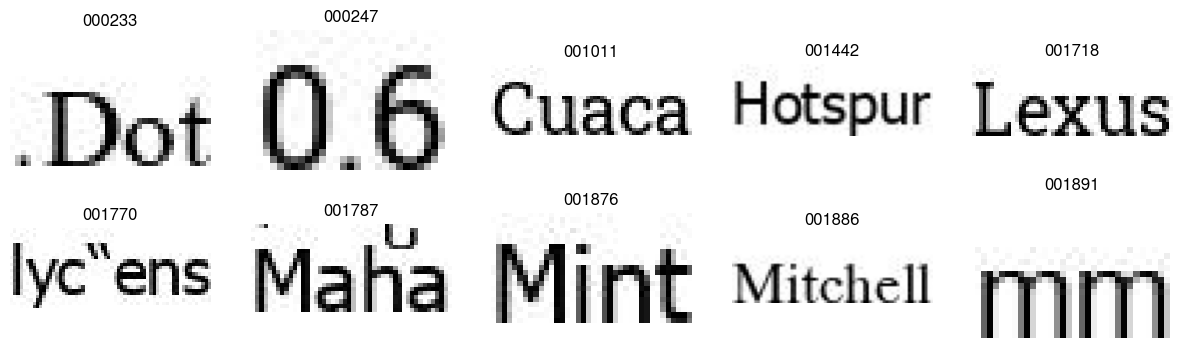

In [5]:
import matplotlib.pyplot as plt
import os

def visualize(dataset_path):
    plt.figure(figsize=(15, 4))
    for i in range(10):
        plt.subplot(2, 5, i+1)
        all_images = os.listdir(f"{dataset_path}/data_train")
        image = plt.imread(f"{dataset_path}/data_train/{all_images[i]}")
        plt.imshow(image)
        plt.axis('off')
        # Setting Khmer font
        plt.rcParams['font.family'] = 'Khmer OS'
        plt.title(all_images[i].split('.')[0], fontname='Khmer OS')
    plt.show()

visualize(DatasetConfig.DATA_ROOT)


## Prepare Dataset

In [6]:
train_df = pd.read_fwf(
    os.path.join(DatasetConfig.DATA_ROOT, 'data_train.txt'), header=None
)
train_df.rename(columns={0: 'file_name', 1: 'text'}, inplace=True)
test_df = pd.read_fwf(
    os.path.join(DatasetConfig.DATA_ROOT, 'data_test.txt'), header=None
)
test_df.rename(columns={0: 'file_name', 1: 'text'}, inplace=True)

In [ ]:
# train_df = pd.read_fwf(os.path.join(DatasetConfig.DATA_ROOT, 'data_train.txt'), header=None)
# train_df.rename(columns={0: 'file_name', 1: 'text'}, inplace=True)

# train_df.head()

In [59]:
train_df.head()

,file_name,text
0,000000.jpg,!(ម៉ានីល
1,000001.jpg,#១
2,000002.jpg,#២
3,000003.jpg,#៥
4,000004.jpg,$109


In [60]:
test_df.head()

,file_name,text
0,022567.jpg,!!!កាលបើ
1,022568.jpg,!Google
2,022569.jpg,$388
3,022570.jpg,$599
4,022571.jpg,(15)


In [ ]:
# Augmentations.
# train_transforms = transforms.Compose([
#     transforms.ColorJitter(brightness=.5, hue=.3),
#     transforms.GaussianBlur(kernel_size=(5, 9), sigma=(0.1, 5)),
# ])

In [87]:
# class CustomOCRDataset(Dataset):
#     def __init__(self, root_dir, df, processor, max_target_length=128):
#         self.root_dir = root_dir
#         self.df = df
#         self.processor = processor
#         self.max_target_length = max_target_length

#     def __len__(self):
#         return len(self.df)

#     def __getitem__(self, idx):
#         # The image file name.
#         file_name = self.df['file_name'][idx]
#         # The text (label).
#         text = self.df['text'][idx]
#         # Read the image, apply augmentations, and get the transformed pixels.
#         image = Image.open(self.root_dir + file_name).convert('RGB')
#         # image = train_transforms(image)
#         pixel_values = self.processor.feature_extractor(image, return_tensors='pt').pixel_values
#         # Pass the text through the tokenizer and get the labels,
#         # i.e. tokenized labels.
#         labels = self.processor.tokenizer(
#             text,
#             padding='max_length',
#             max_length=self.max_target_length
#         ).input_ids
#         # We are using -100 as the padding token.
#         labels = [label if label != self.processor.tokenizer.pad_token_id else -100 for label in labels]
#         encoding = {"pixel_values": pixel_values.squeeze(), "labels": torch.tensor(labels)}
#         return encoding

In [7]:
class CustomOCRDataset(Dataset):
    def __init__(self, root_dir, df, processor, max_target_length=128):
        self.root_dir = root_dir
        self.df = df
        self.processor = processor
        self.max_target_length = max_target_length

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        # The image file name.
        file_name = self.df['file_name'][idx]
        # The text (label).
        text = self.df['text'][idx]
        # Read the image, apply augmentations, and get the transformed pixels.
        image = Image.open(self.root_dir + file_name).convert('RGB')
        # image = train_transforms(image)
        pixel_values = self.processor(image, return_tensors='pt').pixel_values
        # Pass the text through the tokenizer and get the labels,
        # i.e. tokenized labels.
        labels = self.processor.tokenizer(
            text,
            padding='max_length',
            max_length=self.max_target_length
        ).input_ids
        # We are using -100 as the padding token.
        labels = [label if label != self.processor.tokenizer.pad_token_id else -100 for label in labels]
        encoding = {"pixel_values": pixel_values.squeeze(), "labels": torch.tensor(labels)}
        return encoding

In [8]:
# tokenizer = BertTokenizer.from_pretrained("bert-base-multilingual-cased", vocab_file="pretrained_model/bert_module_khmer/assets/vocab_file_BERT_.txt")
tokenizer = NllbTokenizer.from_pretrained("facebook/nllb-200-distilled-600M") # my modified code
# feature_extractor = ViTFeatureExtractor.from_pretrained(ModelConfig.MODEL_NAME)
# tokenizer = BertTokenizer.from_pretrained("bert-base-multilingual-cased")
feature_extractor = ViTFeatureExtractor.from_pretrained(ModelConfig.MODEL_NAME)

processor = TrOCRProcessor(feature_extractor=feature_extractor, tokenizer=tokenizer)
# processor = TrOCRProcessor.from_pretrained(ModelConfig.MODEL_NAME)
train_dataset = CustomOCRDataset(
    root_dir=os.path.join(DatasetConfig.DATA_ROOT, 'data_train/'),
    df=train_df,
    processor=processor
)
valid_dataset = CustomOCRDataset(
    root_dir=os.path.join(DatasetConfig.DATA_ROOT, 'data_test/'),
    df=test_df,
    processor=processor
)

the `lang_code_to_id` attribute is deprecated. The logic is natively handled in the `tokenizer.adder_tokens_decoder` this attribute will be removed in `transformers` v4.38
the `fairseq_tokens_to_ids` attribute is deprecated. The logic is natively handled in the `tokenizer.adder_tokens_decoder` this attribute will be removed in `transformers` v4.38
Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.
/home/EmHengly/miniconda3/envs/khocr/lib/python3.10/site-packages/transformers/models/vit/feature_extraction_vit.py:28: FutureWarning: The class ViTFeatureExtractor is deprecated and will be removed in version 5 of Transformers. Please use ViTImageProcessor instead.
  warnings.warn(
/home/EmHengly/miniconda3/envs/khocr/lib/python3.10/site-packages/transformers/models/trocr/processing_trocr.py:46: FutureWarning: The `feature_extractor` argument is deprecated and will be removed in v5, use `image_processor` instead.
  warnings.w

In [ ]:
# from transformers import BertTokenizer

# # Initialize a Khmer tokenizer (e.g., BERT-based)
# tokenizer = BertTokenizer.from_pretrained("aubmindlab/khbert-base")

# # Khmer text to tokenize
# khmer_text = "សុខ ពិសី លាភ"

# # Tokenize Khmer text
# tokenized_text = tokenizer.encode(khmer_text)

# # Decode tokenized sequence
# decoded_text = tokenizer.decode(tokenized_text)

# print("Tokenized text:", tokenized_text)
# print("Decoded text:", decoded_text)


In [35]:
id =processor.tokenizer.tokenize('ខ្ញុំ')
print(id)

['ខ្ញុំ']


In [31]:
encode = processor.tokenizer.add_tokens(['ខ្ញុំ'])
print (encode)

1


In [10]:
id = processor.tokenizer.encode('១២៣៤')

print("id: ", id)

id:  [256047, 28604, 251131, 251873, 252160, 2]


In [11]:
decode = processor.tokenizer.decode(id) 
print("decode:",decode )

decode: eng_Latn ១២៣៤</s>


In [9]:
print("Number of training examples:", len(train_dataset))
print("Number of validation examples:", len(valid_dataset))

Number of training examples: 22567
Number of validation examples: 5640


In [9]:
encoding = train_dataset[0]
for k,v in encoding.items():
    print(k, v.shape)

pixel_values torch.Size([3, 384, 384])
labels torch.Size([128])


(-0.5, 75.5, 25.5, -0.5)

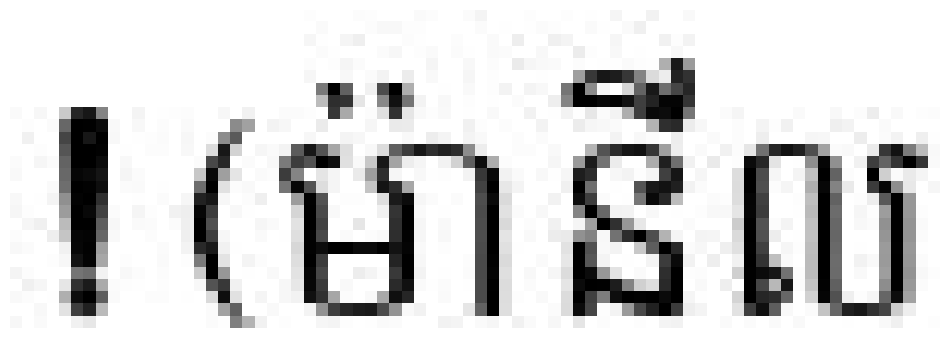

In [14]:
image = Image.open(train_dataset.root_dir + train_df['file_name'][0]).convert("RGB")
# image = train_transforms(image)
plt.imshow(image)
plt.axis('off')

In [10]:
labels = encoding['labels']
labels[labels == -100] = processor.tokenizer.pad_token_id
label_str = processor.decode(labels, skip_special_tokens=True)
print(label_str)

!(ម៉ានីល


In [92]:
# labels = encoding['labels']

# # Replace -100 with pad token id
# labels[labels == -100] = processor.tokenizer.pad_token_id

# # Decode labels
# label_str = processor.tokenizer.decode(labels, skip_special_tokens=True)

# print(label_str)


ម៉ានីល


In [11]:
# Check the tokenizer vocabulary size
vocab_size = processor.tokenizer.vocab_size
print(f"Tokenizer vocabulary size: {vocab_size}")

Tokenizer vocabulary size: 256001


In [28]:
# Example usage assuming `df` is your DataFrame and `processor` is your processor object
# Initialize dataset
dataset = CustomOCRDataset(root_dir='dataset/data_train/', df=train_df, processor=processor, max_target_length=32)

# Example: Print label IDs for the first example in the dataset
print(dataset[1000])


{'pixel_values': tensor([[[1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.],
         ...,
         [1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.]],

        [[1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.],
         ...,
         [1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.]],

        [[1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.],
         ...,
         [1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.]]]), 'labels': tensor([256047,  19947,  32063,      2,   -100,   -100,   -100,   -100,   -100,
          -100,   -100,   -100,   -100,   -100,   -100,   -100,   -100,   -100,
          -100,   -100,   

In [29]:
from transformers import NllbTokenizer

# Example token IDs (replace with actual token IDs from your dataset)
token_ids = [  256047,  19947,  32063,      2,   -100,   -100,   -100]

# Load the tokenizer used in your CustomOCRDataset
# tokenizer = AutoTokenizer.from_pretrained("khmer_tokenizer")
# tokenizer = AutoTokenizer.from_pretrained("GKLMIP/bert-khmer-small-uncased-tokenized")

# Ensure all token IDs are valid
valid_token_ids = [tid for tid in token_ids if tid != -100]

# Decode token IDs to text
decoded_text = processor.batch_decode(valid_token_ids, skip_special_tokens=True)

print("Decoded Text:", decoded_text)


Decoded Text: ['eng_Latn', 'Cr', 'vena', '</s>']


## Initialize the Model

In [16]:
model = VisionEncoderDecoderModel.from_pretrained(ModelConfig.MODEL_NAME, )
model.to(device)
print(model)
# Total parameters and trainable parameters.
total_params = sum(p.numel() for p in model.parameters())
print(f"{total_params:,} total parameters.")
total_trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad)
print(f"{total_trainable_params:,} training parameters.")

Some weights of VisionEncoderDecoderModel were not initialized from the model checkpoint at microsoft/trocr-small-printed and are newly initialized: ['encoder.pooler.dense.bias', 'encoder.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


VisionEncoderDecoderModel(
  (encoder): DeiTModel(
    (embeddings): DeiTEmbeddings(
      (patch_embeddings): DeiTPatchEmbeddings(
        (projection): Conv2d(3, 384, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (encoder): DeiTEncoder(
      (layer): ModuleList(
        (0-11): 12 x DeiTLayer(
          (attention): DeiTAttention(
            (attention): DeiTSelfAttention(
              (query): Linear(in_features=384, out_features=384, bias=True)
              (key): Linear(in_features=384, out_features=384, bias=True)
              (value): Linear(in_features=384, out_features=384, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
            (output): DeiTSelfOutput(
              (dense): Linear(in_features=384, out_features=384, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
          )
          (intermediate): DeiTIntermediate(
            (dense): Linear(

In [17]:
# Resize token embeddings if necessary
model.decoder.resize_token_embeddings(len(tokenizer))

Embedding(256204, 256)

In [14]:
print(model.config)

VisionEncoderDecoderConfig {
  "_name_or_path": "microsoft/trocr-small-printed",
  "architectures": [
    "VisionEncoderDecoderModel"
  ],
  "decoder": {
    "_name_or_path": "",
    "activation_dropout": 0.0,
    "activation_function": "relu",
    "add_cross_attention": true,
    "architectures": null,
    "attention_dropout": 0.0,
    "bad_words_ids": null,
    "begin_suppress_tokens": null,
    "bos_token_id": 0,
    "chunk_size_feed_forward": 0,
    "classifier_dropout": 0.0,
    "cross_attention_hidden_size": 384,
    "d_model": 256,
    "decoder_attention_heads": 8,
    "decoder_ffn_dim": 1024,
    "decoder_layerdrop": 0.0,
    "decoder_layers": 6,
    "decoder_start_token_id": 2,
    "diversity_penalty": 0.0,
    "do_sample": false,
    "dropout": 0.1,
    "early_stopping": false,
    "encoder_no_repeat_ngram_size": 0,
    "eos_token_id": 2,
    "exponential_decay_length_penalty": null,
    "finetuning_task": null,
    "forced_bos_token_id": null,
    "forced_eos_token_id": null

## Model Configurations

In [18]:
# Set special tokens used for creating the decoder_input_ids from the labels.
model.config.decoder_start_token_id = processor.tokenizer.cls_token_id
model.config.pad_token_id = processor.tokenizer.pad_token_id
# Set Correct vocab size.
model.config.vocab_size = model.config.decoder.vocab_size
model.config.eos_token_id = processor.tokenizer.sep_token_id

# model.config.max_length = 64
# model.config.early_stopping = True
# model.config.no_repeat_ngram_size = 3
# model.config.length_penalty = 2.0
# model.config.num_beams = 4

We use the AdamW optimizer here with a weight decay of 0.0005.

In [19]:
optimizer = optim.AdamW(
    model.parameters(), lr=TrainingConfig.LEARNING_RATE, weight_decay=0.0005
)

## Evaluation Metric

In [26]:
cer_metric = evaluate.load('cer')

In [30]:
from datasets import load_metric

cer = load_metric("cer")

/tmp/ipykernel_3241662/1992848031.py:3: FutureWarning: load_metric is deprecated and will be removed in the next major version of datasets. Use 'evaluate.load' instead, from the new library 🤗 Evaluate: https://huggingface.co/docs/evaluate
  cer = load_metric("cer")
/home/EmHengly/miniconda3/envs/khocr/lib/python3.10/site-packages/datasets/load.py:759: FutureWarning: The repository for cer contains custom code which must be executed to correctly load the metric. You can inspect the repository content at https://raw.githubusercontent.com/huggingface/datasets/2.19.2/metrics/cer/cer.py
You can avoid this message in future by passing the argument `trust_remote_code=True`.
Passing `trust_remote_code=True` will be mandatory to load this metric from the next major release of `datasets`.
  warnings.warn(


In [18]:
# def compute_cer(pred):
#     labels_ids = pred.label_ids
#     pred_ids = pred.predictions

#     pred_str = processor.batch_decode(pred_ids, skip_special_tokens=True)
#     labels_ids[labels_ids == -100] = processor.tokenizer.pad_token_id
#     label_str = processor.batch_decode(labels_ids, skip_special_tokens=True)

#     cer = cer_metric.compute(predictions=pred_str, references=label_str)

#     return {"cer": cer}

In [27]:
def compute_cer(pred):
    labels_ids = pred.label_ids
    pred_ids = pred.predictions

    # Decode the predictions and labels
    pred_str = processor.batch_decode(pred_ids, skip_special_tokens=True)
    labels_ids[labels_ids == -100] = processor.tokenizer.pad_token_id
    label_str = processor.batch_decode(labels_ids, skip_special_tokens=True)

    # Check for empty strings in predictions and labels
    empty_label_indices = [i for i, l in enumerate(label_str) if not l]

    if empty_label_indices:
        print(f"Empty labels found at indices: {empty_label_indices}")

    # Filter out empty labels and corresponding predictions
    filtered_pred_str = [p for i, p in enumerate(pred_str) if i not in empty_label_indices]
    filtered_label_str = [l for l in label_str if l]

    # Ensure that the lengths of predictions and labels match after filtering
    if len(filtered_pred_str) != len(filtered_label_str):
        raise ValueError("Mismatch between number of predictions and labels after removing empty strings.")

    # Compute CER
    cer = cer_metric.compute(predictions=filtered_pred_str, references=filtered_label_str)

    return {"cer": cer}


AttributeError: 'VisionEncoderDecoderModel' object has no attribute 'predict'

## Training and Validation Loops

In [21]:
training_args = Seq2SeqTrainingArguments(
    predict_with_generate=True,
    evaluation_strategy='epoch',
    per_device_train_batch_size=TrainingConfig.BATCH_SIZE,
    per_device_eval_batch_size=TrainingConfig.BATCH_SIZE,
    fp16=False,
    output_dir='ocrmodel/',
    logging_strategy='epoch',
    save_strategy='epoch',
    save_total_limit=5,
    report_to='tensorboard',
    num_train_epochs=TrainingConfig.EPOCHS
)

/home/EmHengly/miniconda3/envs/khocr/lib/python3.10/site-packages/transformers/training_args.py:1474: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(


In [22]:
# Initialize trainer.
trainer = Seq2SeqTrainer(
    model=model,
    tokenizer=processor.tokenizer,
    args=training_args,
    compute_metrics=compute_cer,
    train_dataset=train_dataset,
    eval_dataset=valid_dataset,
    data_collator=default_data_collator
)

## Train

In [20]:
res = trainer.train()

/home/EmHengly/.local/lib/python3.10/site-packages/torch/nn/parallel/_functions.py:68: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  warnings.warn('Was asked to gather along dimension 0, but all '


Epoch,Training Loss,Validation Loss,Cer
1,4.914900,3.982836,0.877485
2,3.604800,3.279767,0.760879
3,2.870100,2.683272,0.604280
4,2.235700,2.173844,0.488480
5,1.736200,1.774866,0.379514
6,1.364500,1.551715,0.330239
7,1.090300,1.302652,0.278995
8,0.874300,1.151220,0.228705
9,0.709600,1.039574,0.208977
10,0.576400,0.970274,0.183997


/home/EmHengly/miniconda3/envs/khocr/lib/python3.10/site-packages/transformers/generation/utils.py:1168: UserWarning: Using the model-agnostic default `max_length` (=20) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(


Empty labels found at indices: [5304]


/home/EmHengly/.local/lib/python3.10/site-packages/torch/nn/parallel/_functions.py:68: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  warnings.warn('Was asked to gather along dimension 0, but all '
/home/EmHengly/miniconda3/envs/khocr/lib/python3.10/site-packages/transformers/generation/utils.py:1168: UserWarning: Using the model-agnostic default `max_length` (=20) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(


Empty labels found at indices: [5304]


... (52 outputs left out)

/home/EmHengly/.local/lib/python3.10/site-packages/torch/nn/parallel/_functions.py:68: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  warnings.warn('Was asked to gather along dimension 0, but all '
/home/EmHengly/miniconda3/envs/khocr/lib/python3.10/site-packages/transformers/generation/utils.py:1168: UserWarning: Using the model-agnostic default `max_length` (=20) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(


Empty labels found at indices: [5304]


/home/EmHengly/.local/lib/python3.10/site-packages/torch/nn/parallel/_functions.py:68: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  warnings.warn('Was asked to gather along dimension 0, but all '
/home/EmHengly/miniconda3/envs/khocr/lib/python3.10/site-packages/transformers/generation/utils.py:1168: UserWarning: Using the model-agnostic default `max_length` (=20) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(


Empty labels found at indices: [5304]


In [21]:
res

TrainOutput(global_step=21180, training_loss=0.7557034369568649, metrics={'train_runtime': 24157.458, 'train_samples_per_second': 28.025, 'train_steps_per_second': 0.877, 'total_flos': 1.693831868928177e+20, 'train_loss': 0.7557034369568649, 'epoch': 30.0})

## Inference

In [35]:
device = torch.device('cuda:0' if torch.cuda.is_available else 'cpu')

In [23]:
# processor = TrOCRProcessor.from_pretrained(ModelConfig.MODEL_NAME)
trained_model = VisionEncoderDecoderModel.from_pretrained('ocrmodel/checkpoint-21180').to(device)

In [44]:
from torch.utils.data import DataLoader

test_dataloader = DataLoader(valid_dataset, batch_size=8)

In [45]:
batch = next(iter(test_dataloader))

In [46]:
for k,v in batch.items():
  print(k, v.shape)

pixel_values torch.Size([8, 3, 384, 384])
labels torch.Size([8, 128])


In [47]:
labels = batch["labels"]
labels[labels == -100] = processor.tokenizer.pad_token_id
label_str = processor.batch_decode(labels, skip_special_tokens=True)
label_str

['!!!កាលបើ', '!Google', '$388', '$599', '(15)', '(21.9', '(Ajax)', '(Android']

In [48]:
# processor = TrOCRProcessor.from_pretrained(ModelConfig.MODEL_NAME)
trained_model = VisionEncoderDecoderModel.from_pretrained('ocrmodel/checkpoint-21180').to(device)

In [49]:
from datasets import load_metric

cer = load_metric("cer")

/home/EmHengly/miniconda3/envs/khocr/lib/python3.10/site-packages/datasets/load.py:759: FutureWarning: The repository for cer contains custom code which must be executed to correctly load the metric. You can inspect the repository content at https://raw.githubusercontent.com/huggingface/datasets/2.19.2/metrics/cer/cer.py
You can avoid this message in future by passing the argument `trust_remote_code=True`.
Passing `trust_remote_code=True` will be mandatory to load this metric from the next major release of `datasets`.
  warnings.warn(


In [51]:
from tqdm.notebook import tqdm

print("Running evaluation...")

for batch in tqdm(test_dataloader):
    # predict using generate
    pixel_values = batch["pixel_values"].to(device)
    outputs = model.generate(pixel_values)

    # decode
    pred_str = processor.batch_decode(outputs, skip_special_tokens=True)
    labels = batch["labels"]
    labels[labels == -100] = processor.tokenizer.pad_token_id
    label_str = processor.batch_decode(labels, skip_special_tokens=True)
    
     # Check for empty strings in predictions and labels
    empty_label_indices = [i for i, l in enumerate(label_str) if not l]

    if empty_label_indices:
        print(f"Empty labels found at indices: {empty_label_indices}")

    # Filter out empty labels and corresponding predictions
    filtered_pred_str = [p for i, p in enumerate(pred_str) if i not in empty_label_indices]
    filtered_label_str = [l for l in label_str if l]

    # Ensure that the lengths of predictions and labels match after filtering
    if len(filtered_pred_str) != len(filtered_label_str):
        raise ValueError("Mismatch between number of predictions and labels after removing empty strings.")


    # add batch to metric
    cer.add_batch(predictions=pred_str, references=label_str)

final_score = cer.compute()

Running evaluation...


  0%|          | 0/705 [00:00<?, ?it/s]

Empty labels found at indices: [0]


ValueError: one or more references are empty strings

In [53]:
from tqdm.notebook import tqdm
import torch
from datasets import load_metric

print("Running evaluation...")

# Ensure the model is in evaluation mode
trained_model.eval()

# Device configuration
# device = "cuda" if torch.cuda.is_available() else "cpu"
# model.to(device)

# Initialize an empty list to collect predictions and labels
all_predictions = []
all_labels = []

# Load the CER metric
cer = load_metric("cer")

# Evaluation loop
for batch in tqdm(test_dataloader):
    # Predict using generate
    pixel_values = batch["pixel_values"].to(device)
    with torch.no_grad():
        outputs = model.generate(pixel_values)

    # Decode predictions and labels
    pred_str = processor.batch_decode(outputs, skip_special_tokens=True)
    labels = batch["labels"]
    labels[labels == -100] = processor.tokenizer.pad_token_id
    label_str = processor.batch_decode(labels, skip_special_tokens=True)

    # Filter out empty strings
    filtered_pred_str = [p for p in pred_str if p.strip()]
    filtered_label_str = [l for l in label_str if l.strip()]

    # Log mismatched cases
    if len(filtered_pred_str) != len(filtered_label_str):
        print(f"Mismatch found. Skipping this batch. Predictions: {len(filtered_pred_str)}, Labels: {len(filtered_label_str)}")
        continue

    # Add filtered predictions and labels to the lists
    all_predictions.extend(filtered_pred_str)
    all_labels.extend(filtered_label_str)

# Compute CER
cer.add_batch(predictions=all_predictions, references=all_labels)
final_score = cer.compute()

print(f"Final CER score: {final_score}")


Running evaluation...


/home/EmHengly/miniconda3/envs/khocr/lib/python3.10/site-packages/datasets/load.py:759: FutureWarning: The repository for cer contains custom code which must be executed to correctly load the metric. You can inspect the repository content at https://raw.githubusercontent.com/huggingface/datasets/2.19.2/metrics/cer/cer.py
You can avoid this message in future by passing the argument `trust_remote_code=True`.
Passing `trust_remote_code=True` will be mandatory to load this metric from the next major release of `datasets`.
  warnings.warn(


  0%|          | 0/705 [00:00<?, ?it/s]

/home/EmHengly/miniconda3/envs/khocr/lib/python3.10/site-packages/transformers/generation/utils.py:1168: UserWarning: Using the model-agnostic default `max_length` (=20) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(


Mismatch found. Skipping this batch. Predictions: 8, Labels: 7
Final CER score: 1.2253891428400705


In [ ]:
print("Character error rate on test set:", final_score)

In [34]:
import torch
from torch.utils.data import DataLoader
from transformers import VisionEncoderDecoderModel, AutoTokenizer, AutoProcessor

# # Load your model and processor
# model = VisionEncoderDecoderModel.from_pretrained("your-model-checkpoint")
# processor = AutoProcessor.from_pretrained("your-model-checkpoint")

# Ensure model is in evaluation mode
trained_model.eval()

# Define the DataLoader for your dataset
def create_dataloader(dataset, batch_size=16):
    return DataLoader(dataset, batch_size=batch_size)

# Define the function to generate predictions
def generate_predictions(model, processor, dataloader):
    predictions = []
    labels = []
    
    for batch in dataloader:
        # Assuming batch contains the necessary inputs for the model
        inputs = processor(images=batch["image"], return_tensors="pt").to(model.device)
        with torch.no_grad():
            outputs = model.generate(inputs["pixel_values"])
        
        # Decode the predictions and labels
        pred_str = processor.batch_decode(outputs, skip_special_tokens=True)
        label_str = processor.batch_decode(batch["labels"], skip_special_tokens=True)
        
        predictions.extend(pred_str)
        labels.extend(label_str)
    
    return {"predictions": predictions, "label_ids": labels}

# Compute and print CER
def evaluate_and_print_cer(dataset, description, batch_size=16):
    dataloader = create_dataloader(dataset, batch_size)
    preds = generate_predictions(model, processor, dataloader)
    cer_results = compute_cer(preds)
    print(f"{description} CER: {cer_results['cer']}")

# Evaluate CER for the test set
evaluate_and_print_cer(valid_dataset, "Test set")

# Evaluate CER for the training set
evaluate_and_print_cer(train_dataset, "Training set")


KeyError: 'image'

In [43]:
def evaluate_and_print_cer(dataset):
    # Create a prediction object (this is just a placeholder, replace it with actual predictions)
    predictions = trained_model.eval(dataset)
    
    # Compute CER
    cer_results = compute_cer(predictions)
    
    # Print the CER for the dataset
    print(f"CER: {cer_results['cer']}")

# Evaluate CER for the test set
evaluate_and_print_cer(valid_dataset, "Test set")

# Evaluate CER for the training set
evaluate_and_print_cer(train_dataset, "Training set")

TypeError: evaluate_and_print_cer() takes 1 positional argument but 2 were given

In [35]:
print(res.global_step)

21180


In [39]:


# # Specify the checkpoint path
# checkpoint_path = 'ocrmodel/checkpoint-19062'

# # Load the model from the checkpoint
# trained_model = VisionEncoderDecoderModel.from_pretrained(checkpoint_path).to(device)

# # trained_model = VisionEncoderDecoderModel.from_pretrained('ocrmodel/checkpoint-'+str(res.global_step)).to(device)

In [21]:
def read_and_show(image_path):
    """
    :param image_path: String, path to the input image.

    Returns:
        image: PIL Image.
    """
    image = Image.open(image_path).convert('RGB')
    return image

In [22]:
def ocr(image, processor, model):
    """
    :param image: PIL Image.
    :param processor: Huggingface OCR processor.
    :param model: Huggingface OCR model.

    Returns:
        generated_text: the OCR'd text string.
    """
    # We can directly perform OCR on cropped images.
    pixel_values = processor(image, return_tensors='pt').pixel_values.to(device)
    generated_ids = model.generate(pixel_values)
    generated_text = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]
    return generated_text

In [23]:
def eval_new_data(
    data_path=os.path.join(DatasetConfig.DATA_ROOT, 'data_test', '*'),
    num_samples=50
):
    image_paths = glob.glob(data_path)
    for i, image_path in tqdm(enumerate(image_paths), total=len(image_paths)):
        if i == num_samples:
            break
        image = read_and_show(image_path)
        text = ocr(image, processor, trained_model)
        plt.figure(figsize=(7, 4))
        plt.imshow(image)
        plt.title(text)
        plt.axis('off')
        plt.show()
        print('Generated text:', text)

  0%|          | 0/5640 [00:00<?, ?it/s]

/home/EmHengly/miniconda3/envs/khocr/lib/python3.10/site-packages/transformers/generation/utils.py:1168: UserWarning: Using the model-agnostic default `max_length` (=20) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(


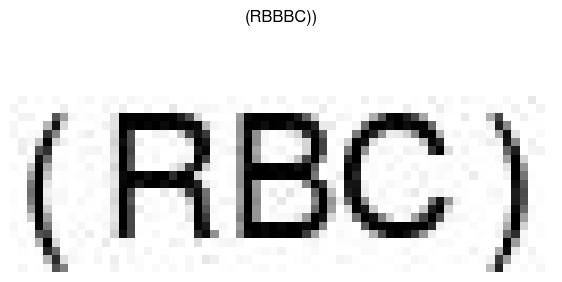

Generated text: (RBBBC))


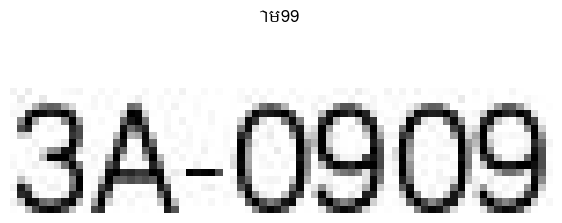

Generated text: ាម99


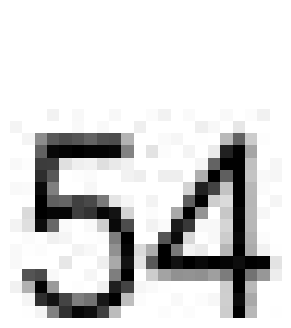

Generated text: 


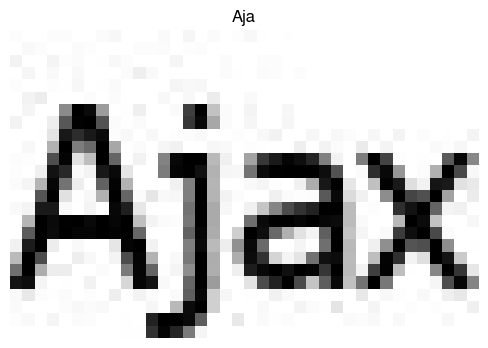

Generated text: Aja


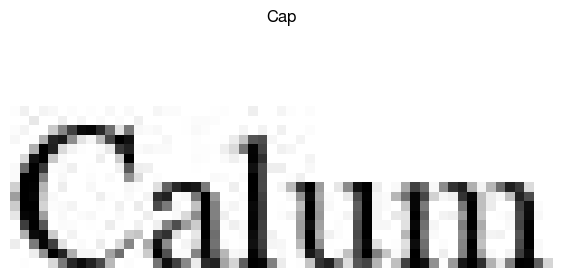

Generated text: Cap


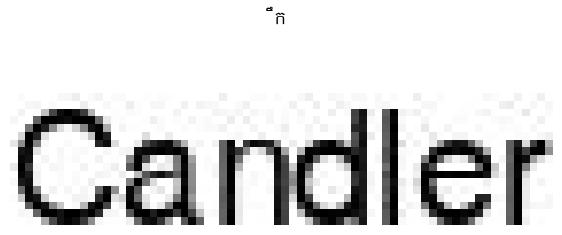

Generated text: ឹក


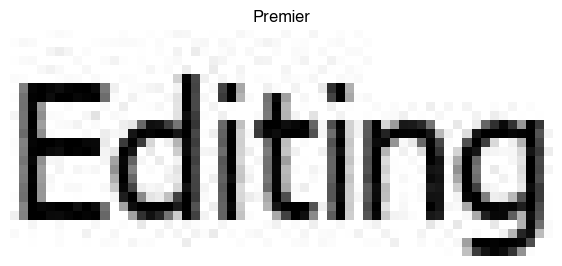

Generated text: Premier


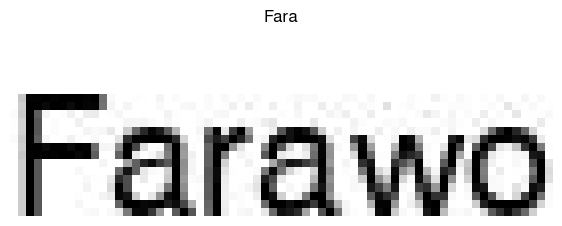

Generated text: Fara


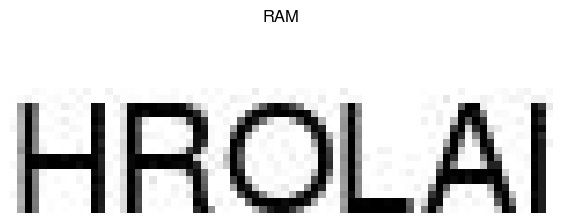

Generated text: RAM


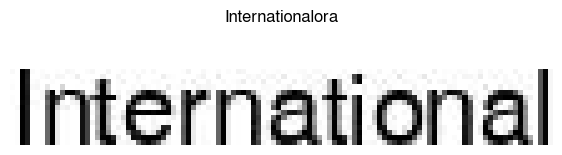

Generated text: Internationalora


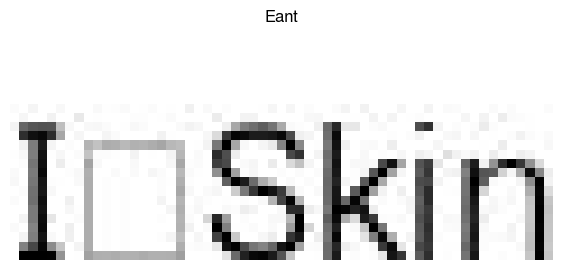

Generated text: Eant


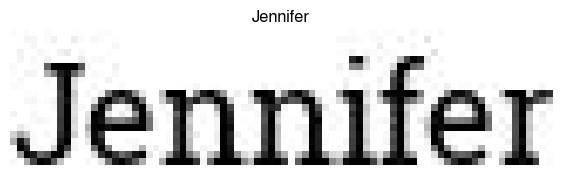

Generated text: Jennifer


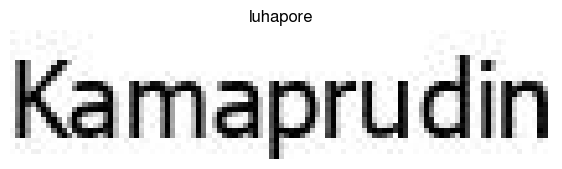

Generated text: luhapore


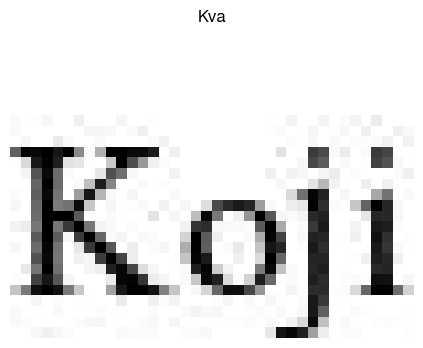

Generated text: Kva


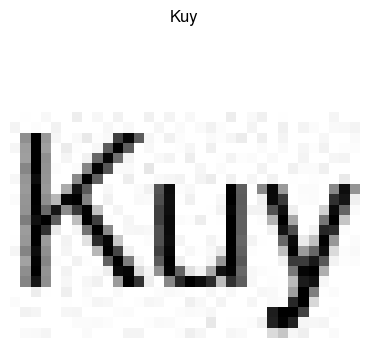

Generated text: Kuy


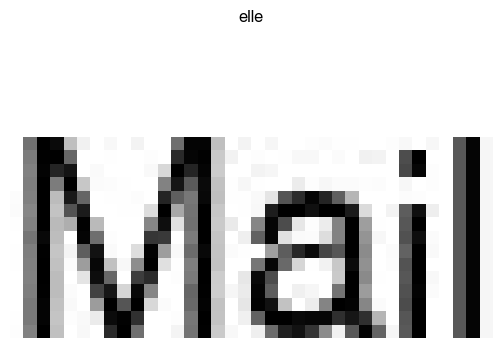

Generated text: elle


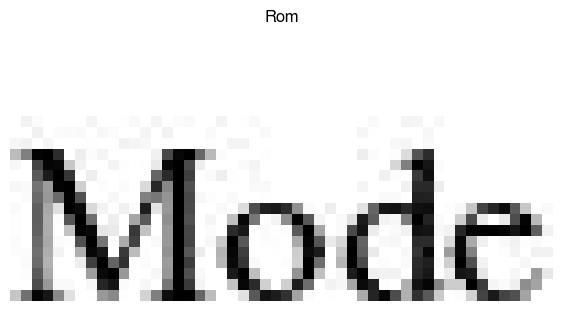

Generated text: Rom


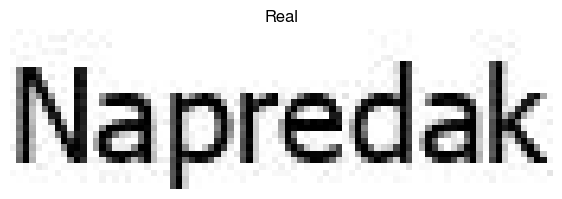

Generated text: Real


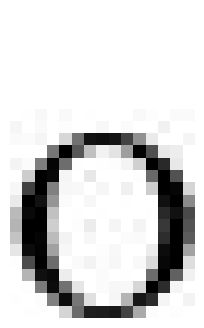

Generated text: 


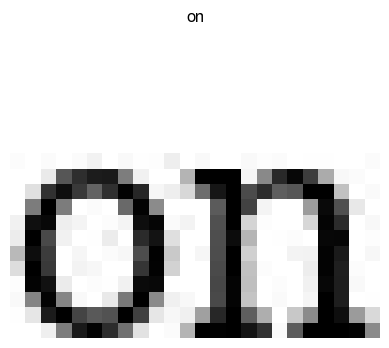

Generated text: on


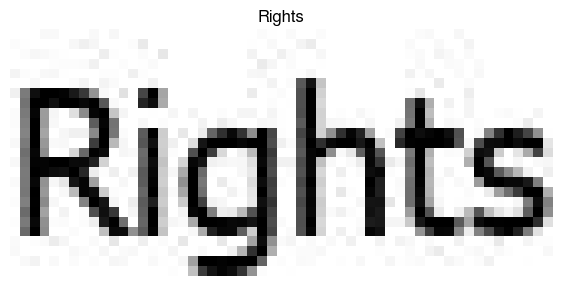

Generated text: Rights


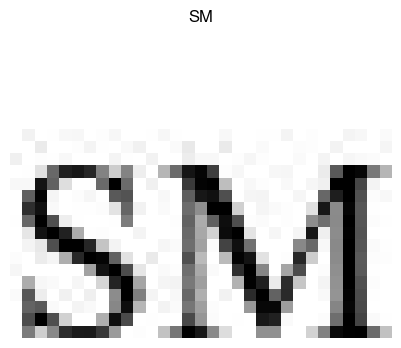

Generated text: SM


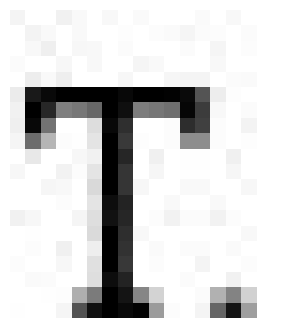

Generated text: 


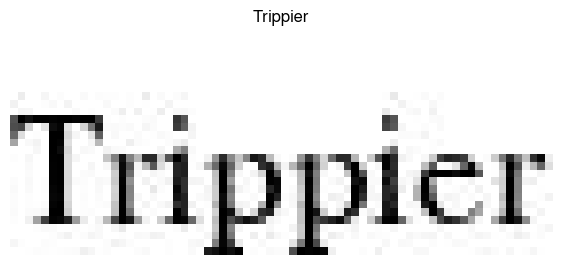

Generated text: Trippier


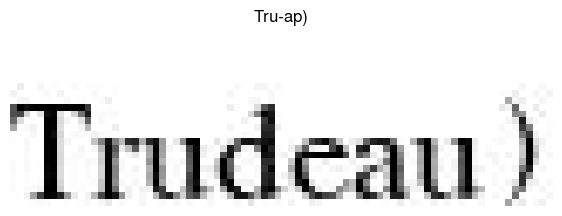

Generated text: Tru-ap)


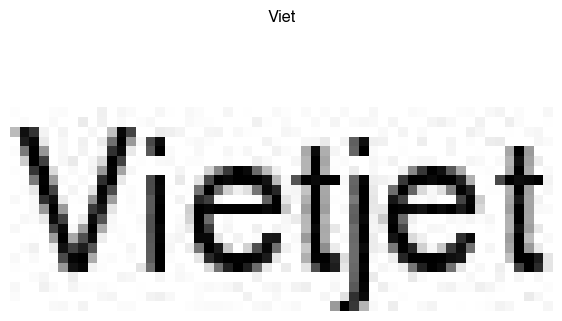

Generated text: Viet


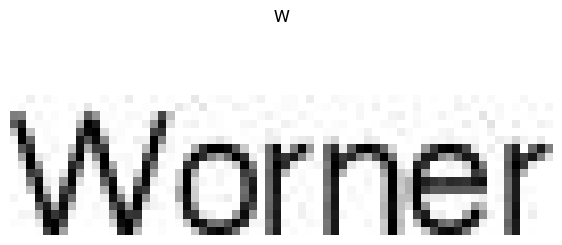

Generated text: W


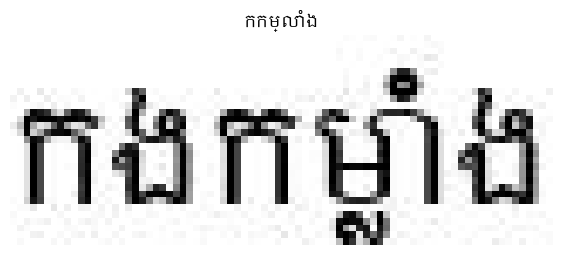

Generated text: កកម្លាំង


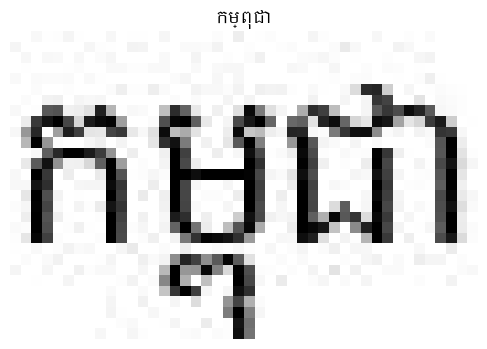

Generated text: កម្ពុជា


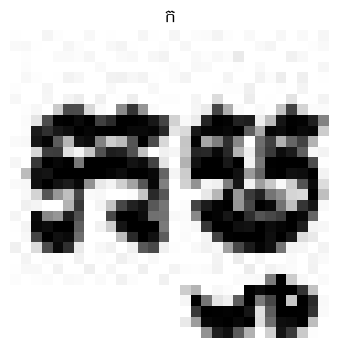

Generated text: ក


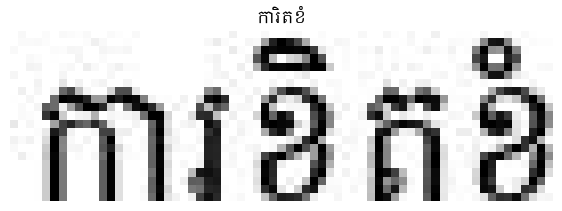

Generated text: ការិតខំ


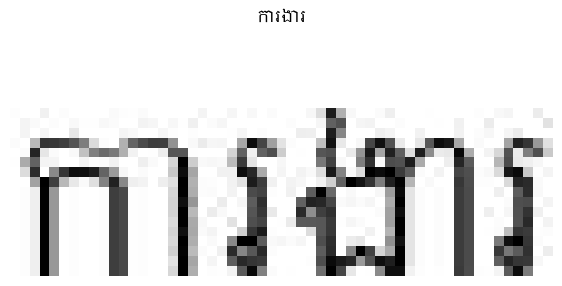

Generated text: ការងារ


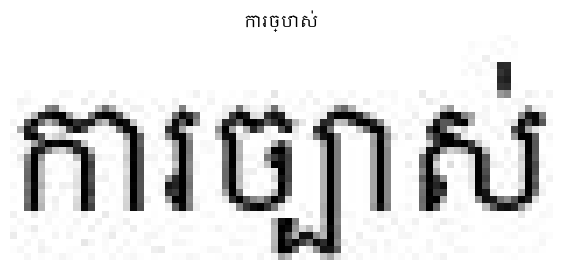

Generated text: ការច្បាស់


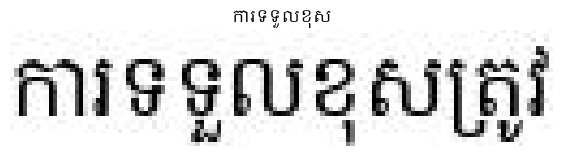

Generated text: ការទទួលខុស


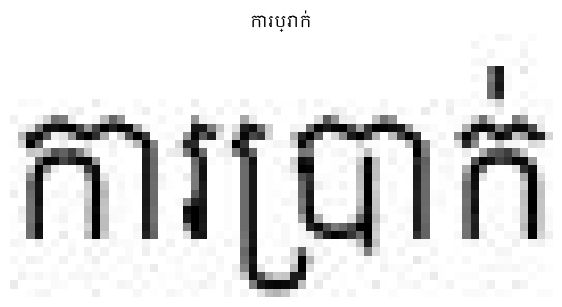

Generated text: ការប្រាក់


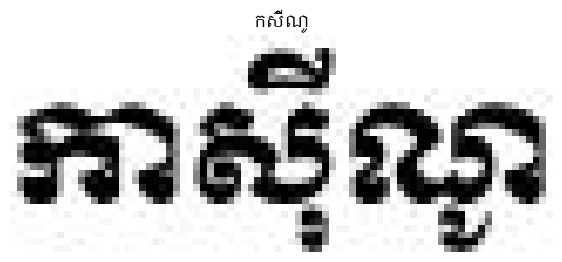

Generated text: កស៊ីណូ


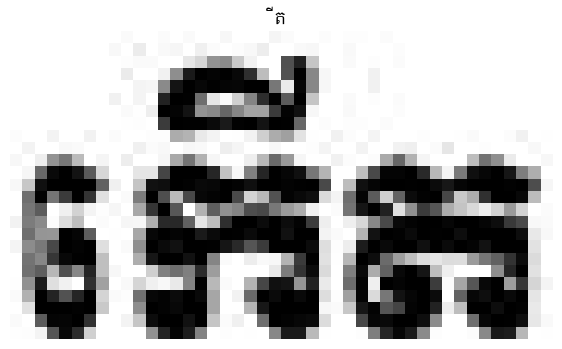

Generated text: ីីត


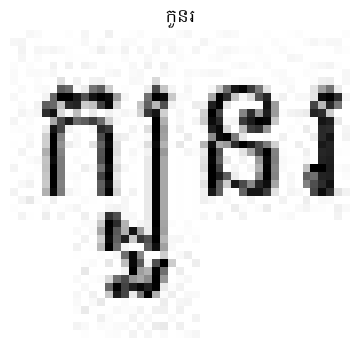

Generated text: កួនរ


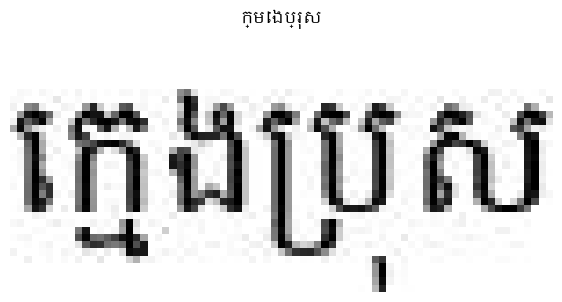

Generated text: ក្មេងប្រុស


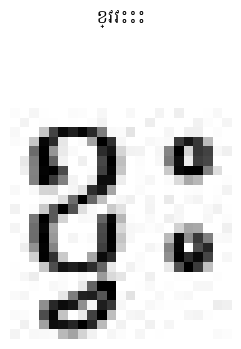

Generated text: ខ្វវះះះ


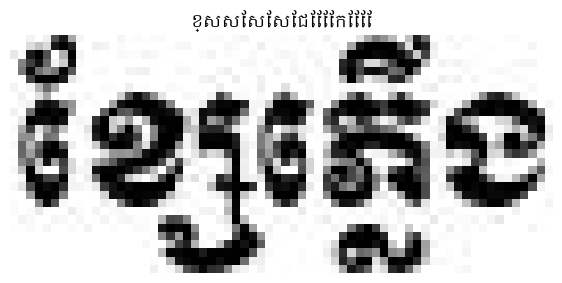

Generated text: ខ្សសែសែសែជែែែែកែែែែ


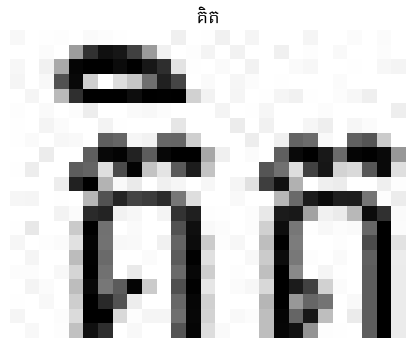

Generated text: គិត


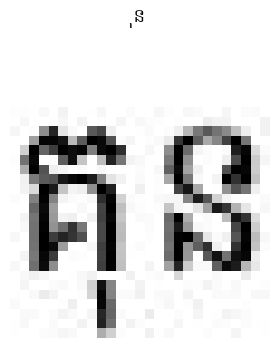

Generated text: ុន


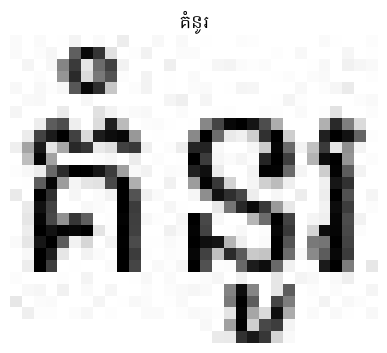

Generated text: គំនូរ


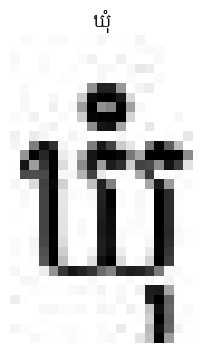

Generated text: ឃុំ


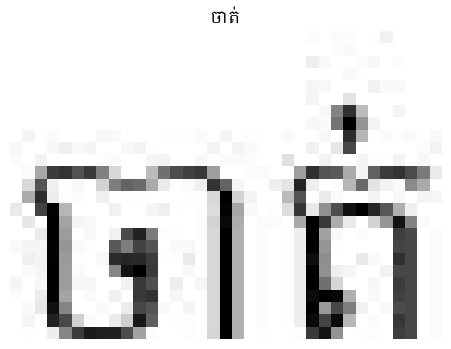

Generated text: ចាត់


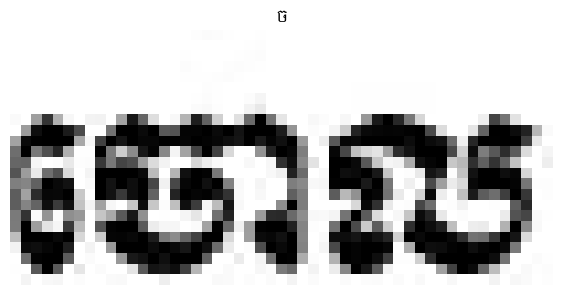

Generated text: ច


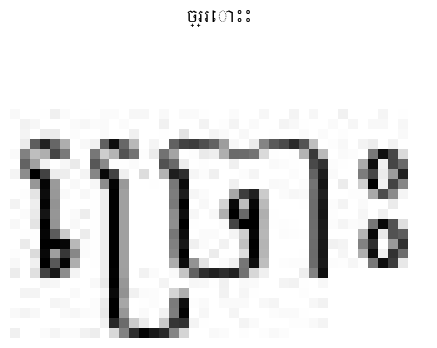

Generated text: ច្រ្រោះះ


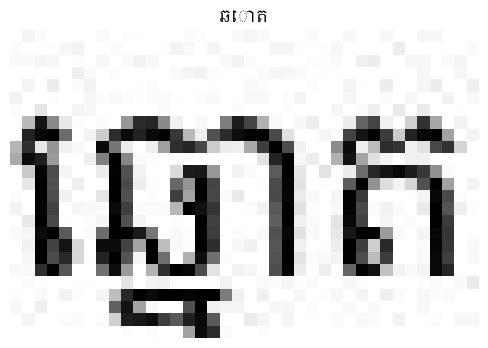

Generated text: ឆោត


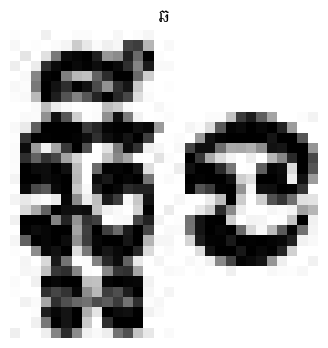

Generated text: ឆ


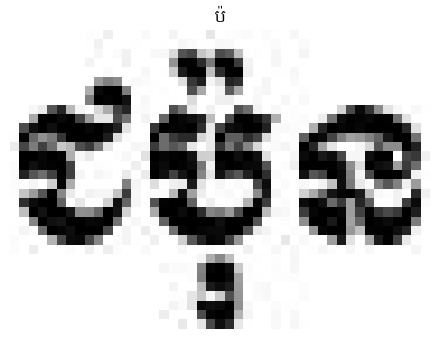

Generated text: ប៉


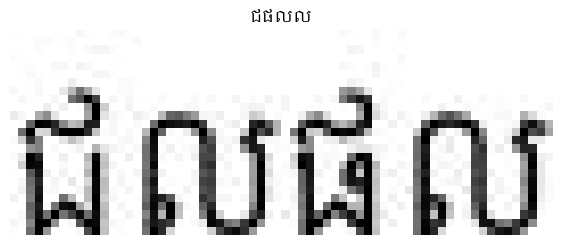

Generated text: ជផលល


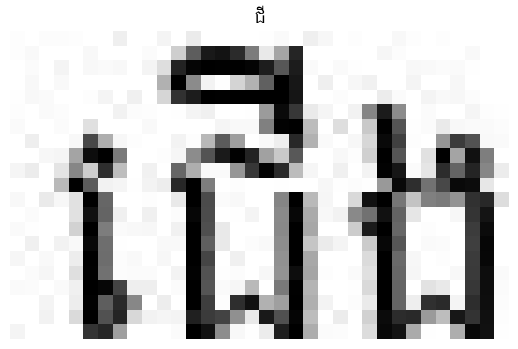

Generated text: ជី


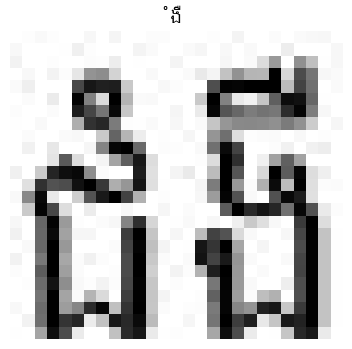

Generated text: ំងឺ


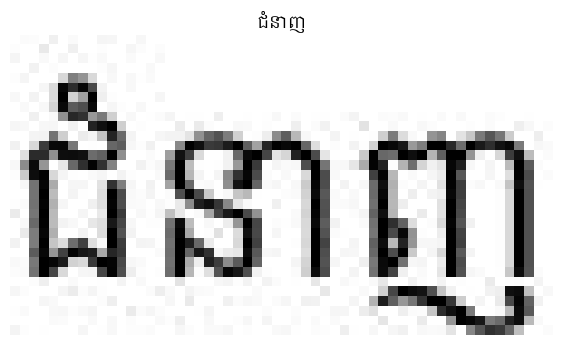

Generated text: ជំនាញ


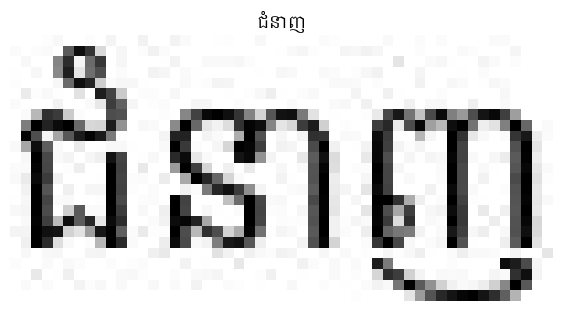

Generated text: ជំនាញ


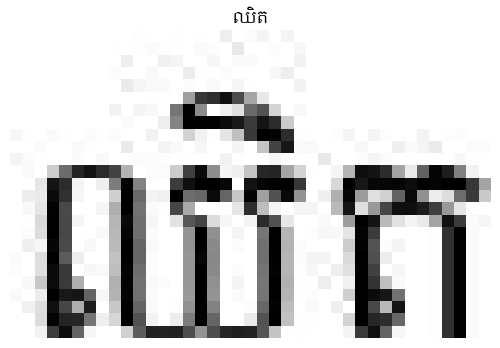

Generated text: ឈិត


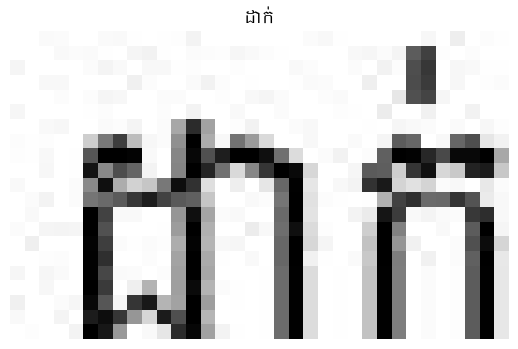

Generated text: ដាក់


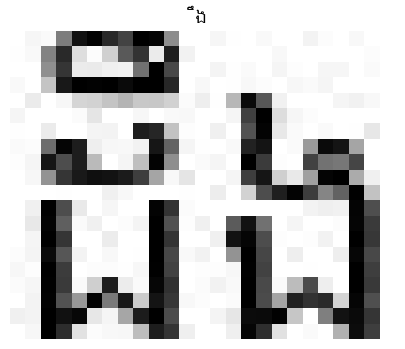

Generated text: ឹង


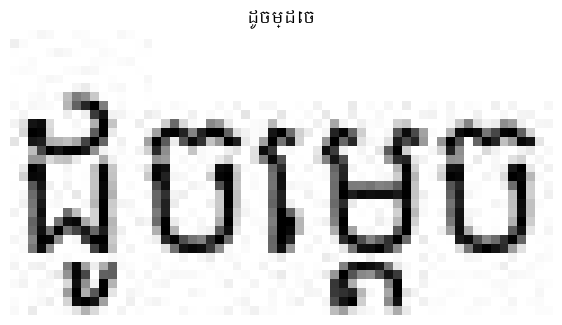

Generated text: ដូចម្ដេច


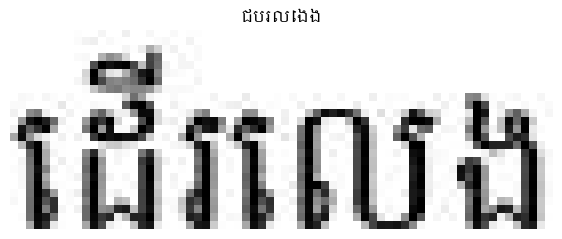

Generated text: ជបរលេងង


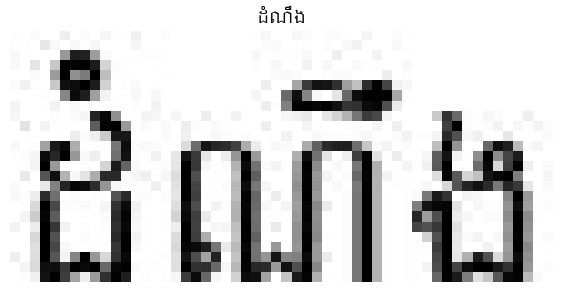

Generated text: ដំណឹង


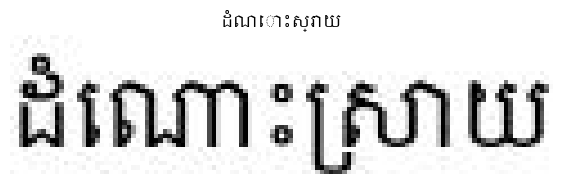

Generated text: ដំណោះស្រាយ


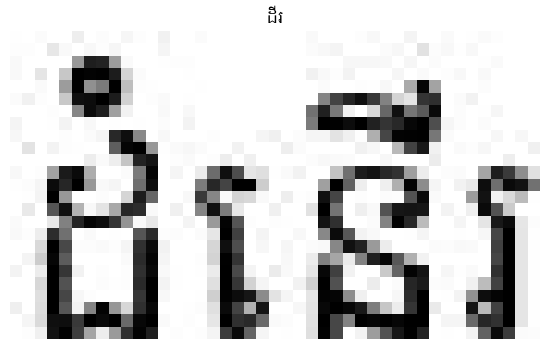

Generated text: ដីរ


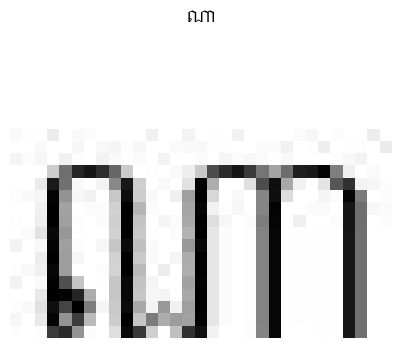

Generated text: ណា


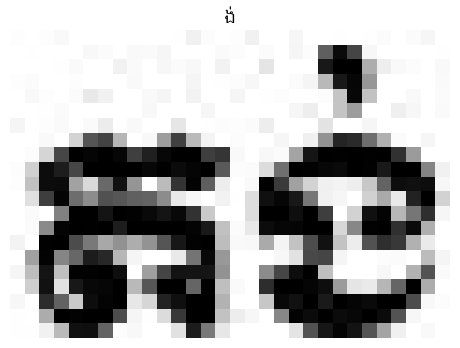

Generated text: ង់


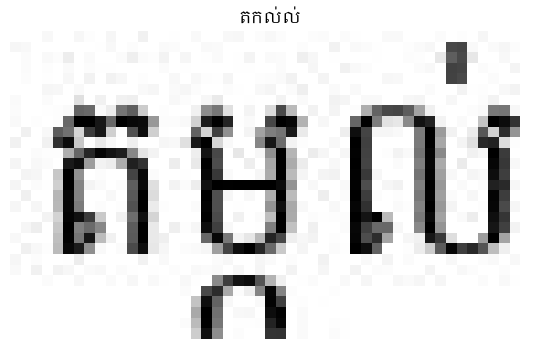

Generated text: តកល់ល់


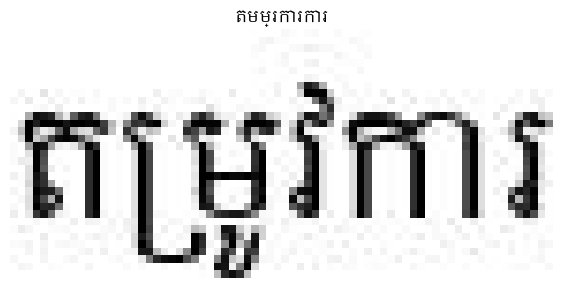

Generated text: តមម្រការការ


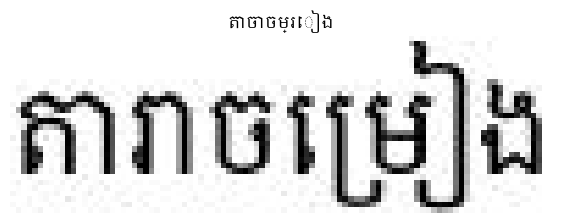

Generated text: តាចាចម្រៀង


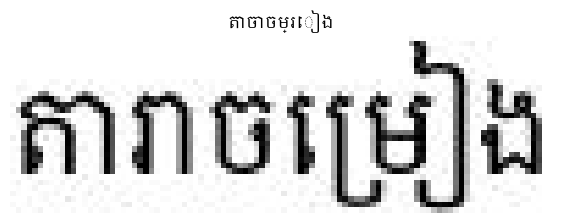

Generated text: តាចាចម្រៀង


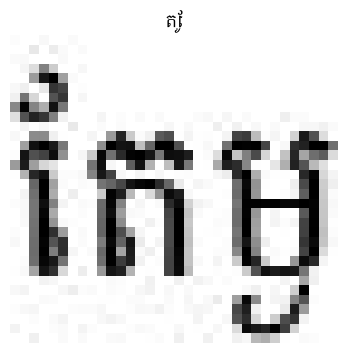

Generated text: តែូ


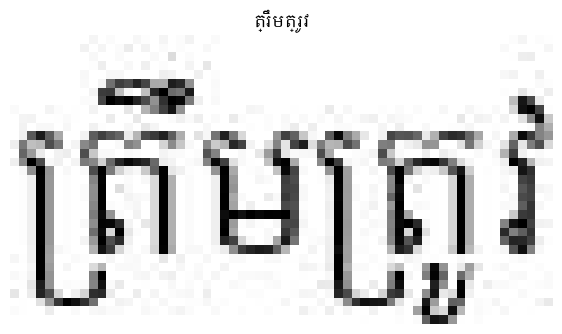

Generated text: ត្រឹមត្រូវ


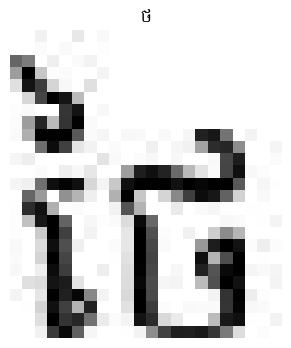

Generated text: ថ


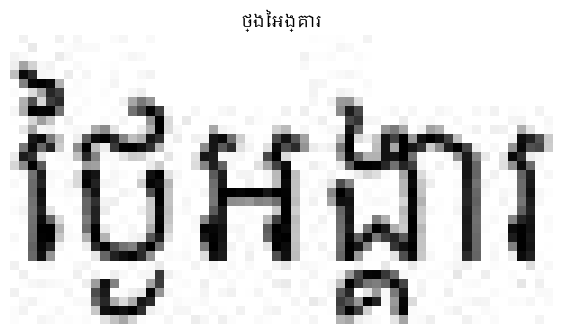

Generated text: ថ្ងៃអង្គារ


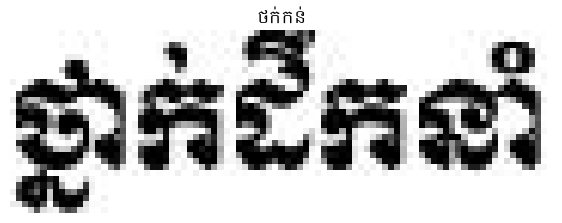

Generated text: ថក់កន់


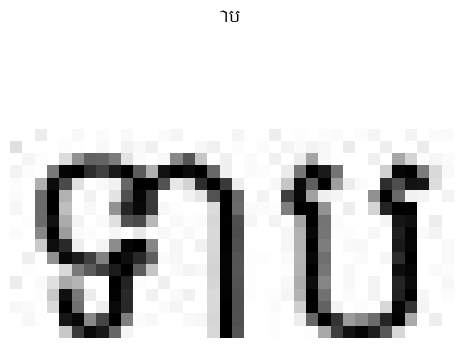

Generated text: ាប


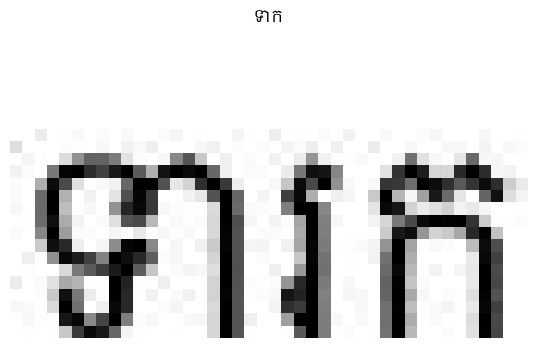

Generated text: ទាក


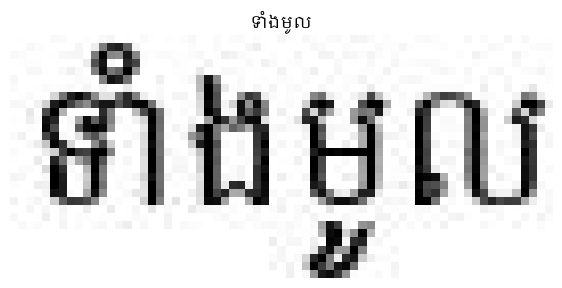

Generated text: ទាំងមូល


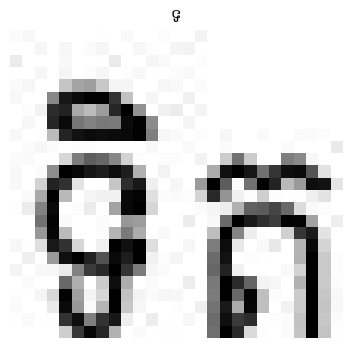

Generated text: ទ


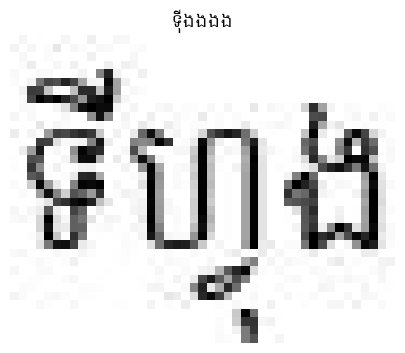

Generated text: ទីុងងងង


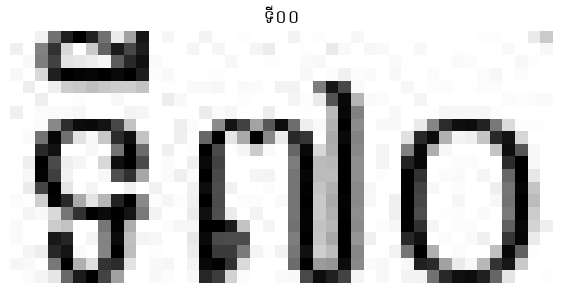

Generated text: ទី០០


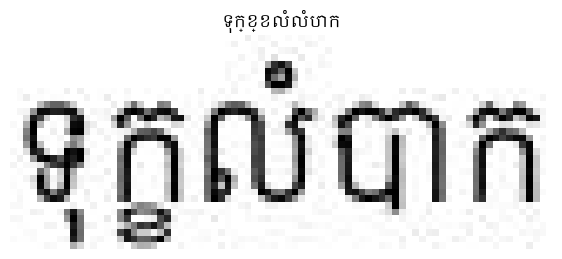

Generated text: ទុក្ខ្ខលំលំបាក


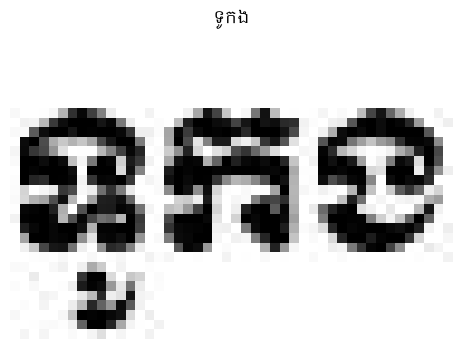

Generated text: ទូកង


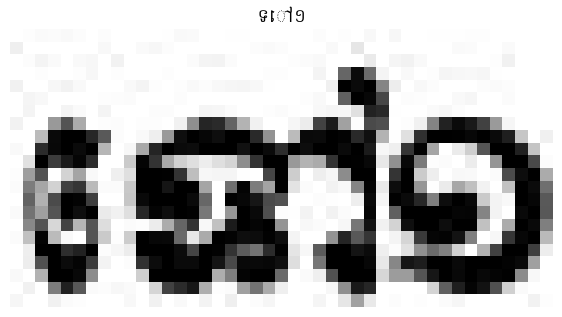

Generated text: ទៅ១


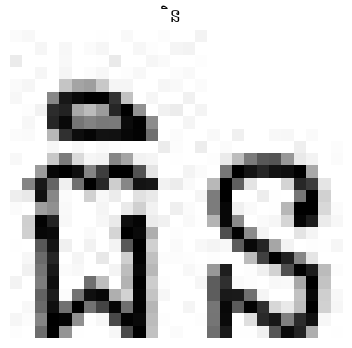

Generated text: ិន


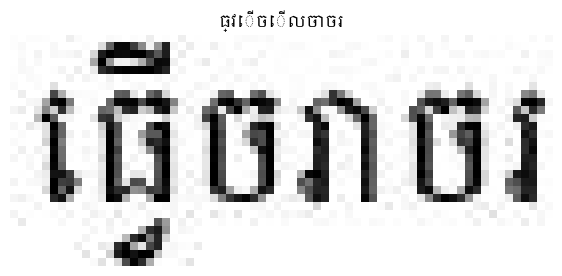

Generated text: ធ្វើចើលចាចរ


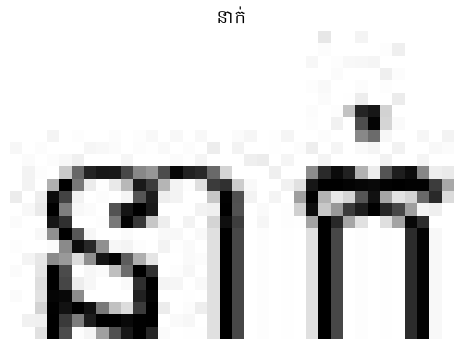

Generated text: នាក់


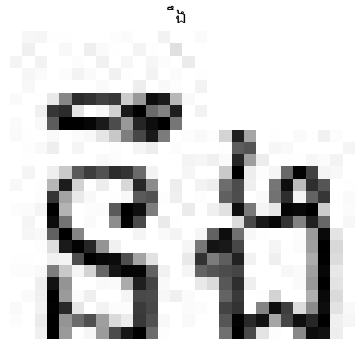

Generated text: ឹង


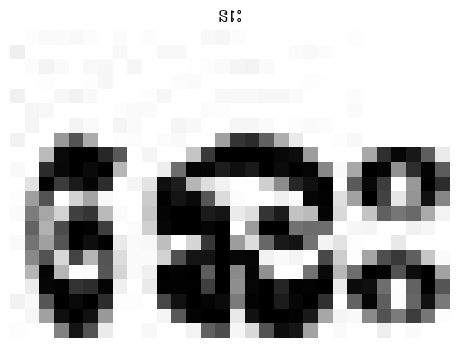

Generated text: នេះ


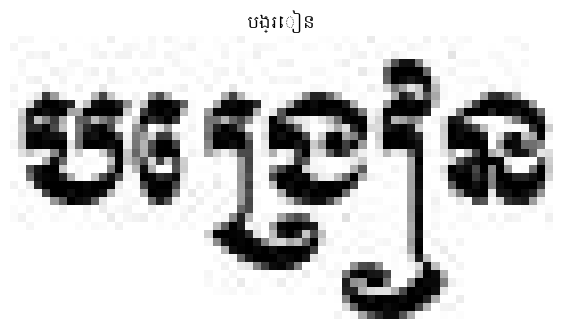

Generated text: បង្រៀន


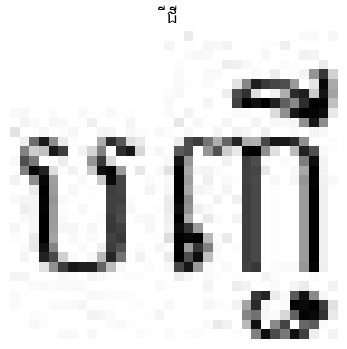

Generated text: ីជី


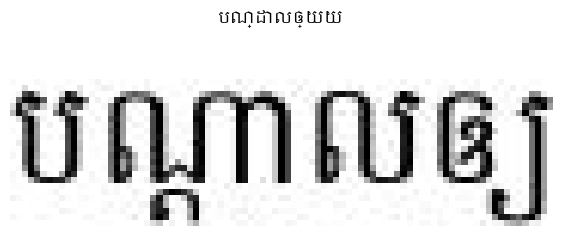

Generated text: បណ្ដាលឲ្យយ


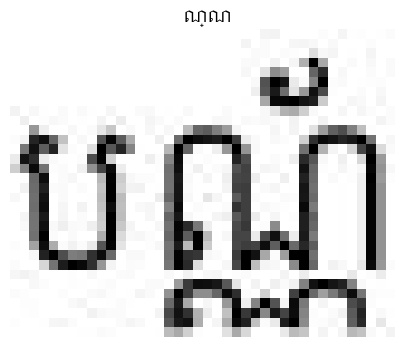

Generated text: ណ្ណ


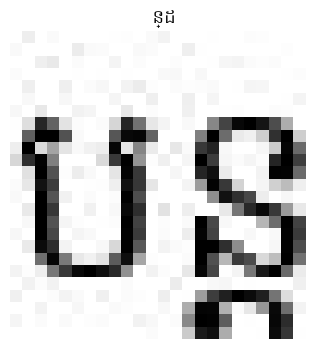

Generated text: ន្ដ


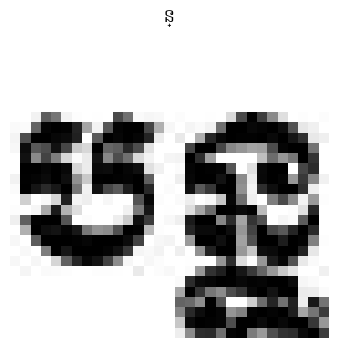

Generated text: ន្


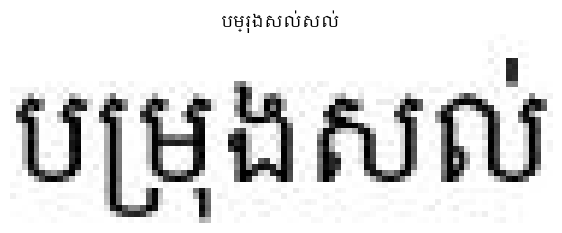

Generated text: បម្រុងសល់សល់


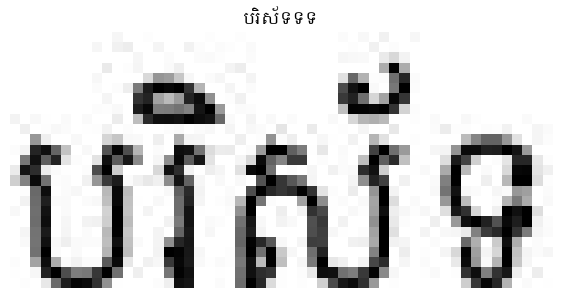

Generated text: បរិស័ទទទ


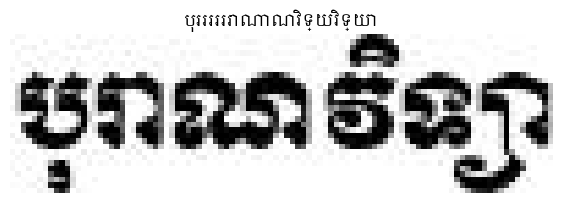

Generated text: បុររររររាណាណវិទ្យវិទ្យា


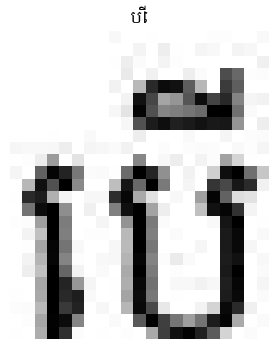

Generated text: បេីី


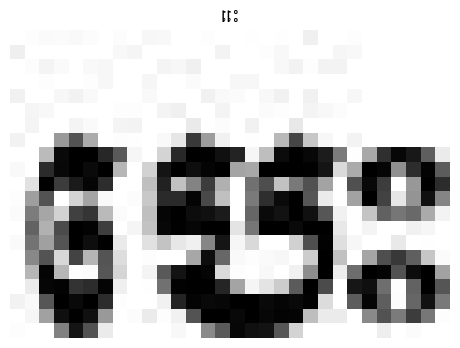

Generated text: េេះ


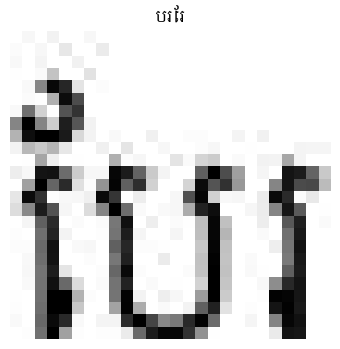

Generated text: បរែរ


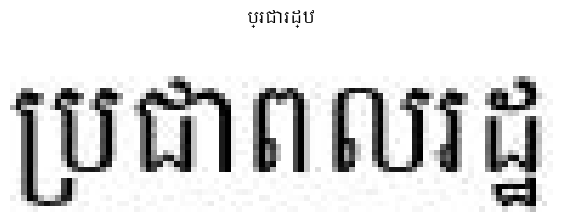

Generated text: ប្រជារដ្ឋ


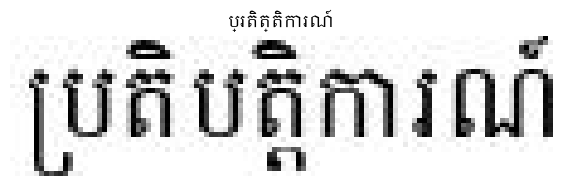

Generated text: ប្រតិត្តិការណ៍


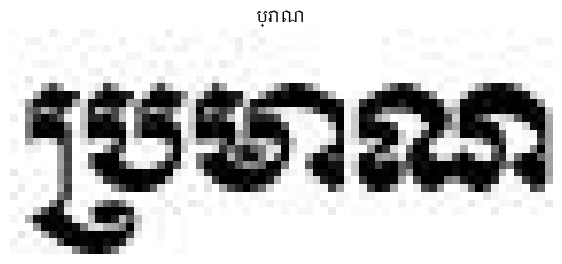

Generated text: ប្រាណ


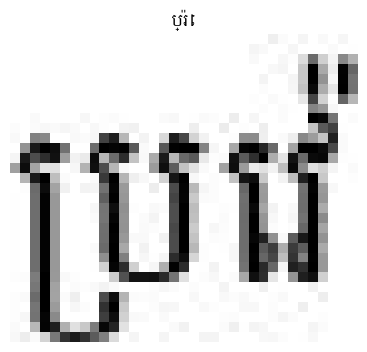

Generated text: ប្រ៉េ


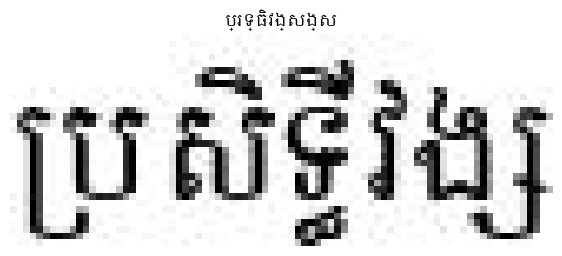

Generated text: ប្រទ្ធិវង្សង្ស


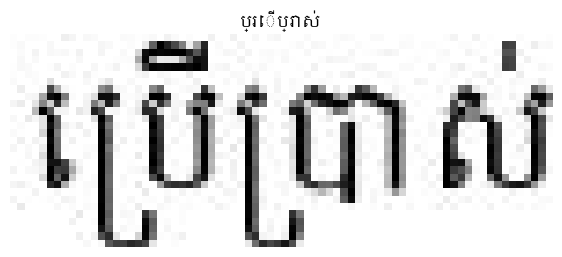

Generated text: ប្រើប្រាស់


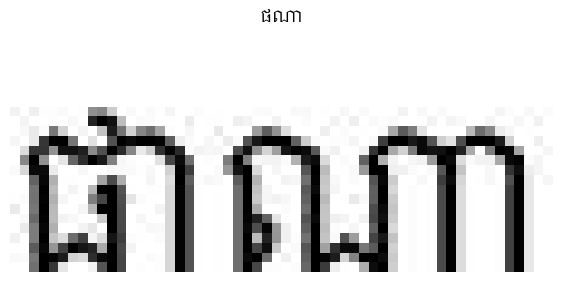

Generated text: ផណា


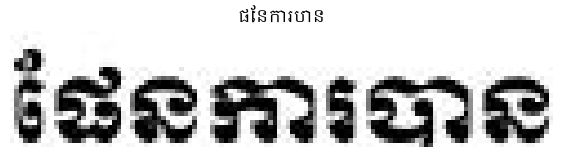

Generated text: ផែនការបាន


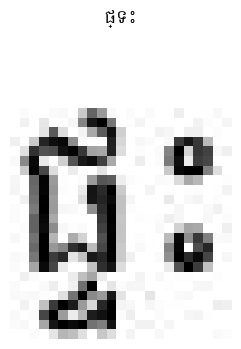

Generated text: ផ្ទះ


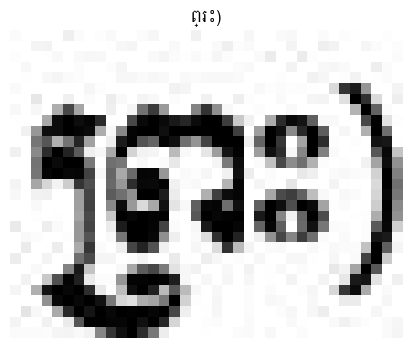

Generated text: ព្រះ)


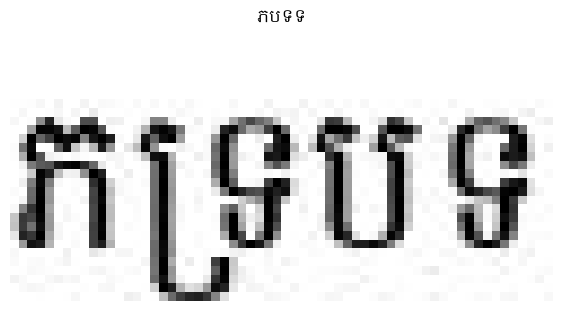

Generated text: ភបទទ


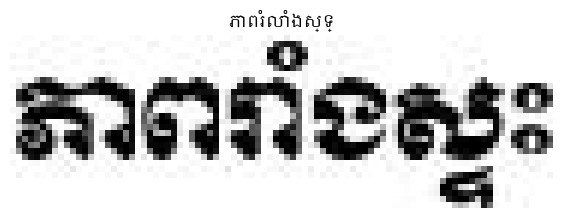

Generated text: ភាពរំលាំងស្ទ្


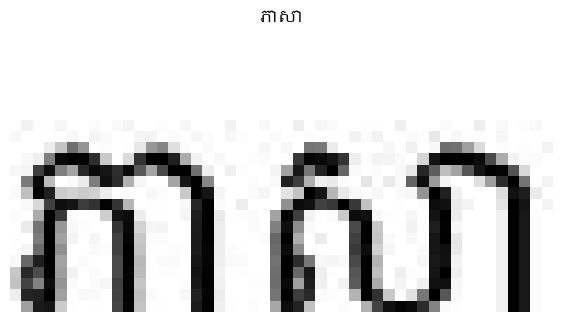

Generated text: ភាសា


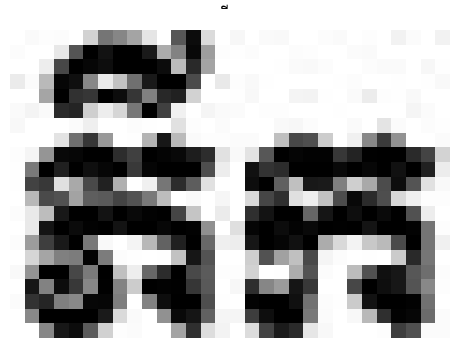

Generated text: ី


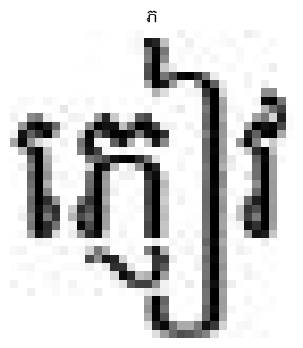

Generated text: ភ


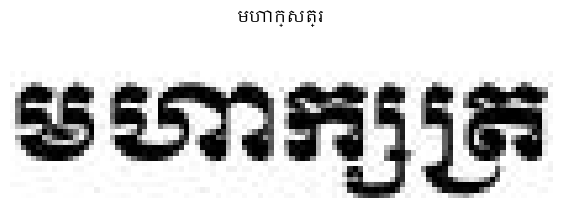

Generated text: មហាក្សត្រ


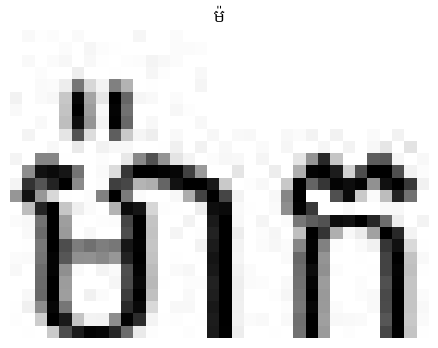

Generated text: ម៉


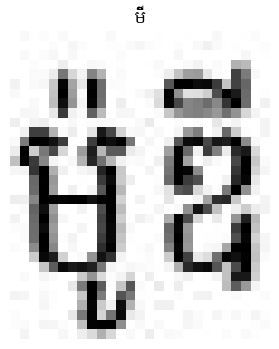

Generated text: ម៉ី


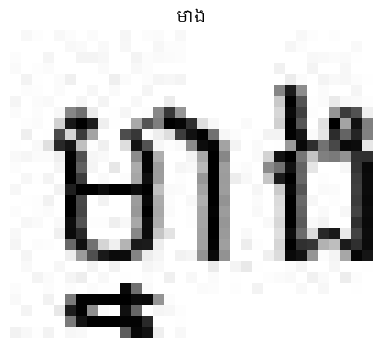

Generated text: មាង


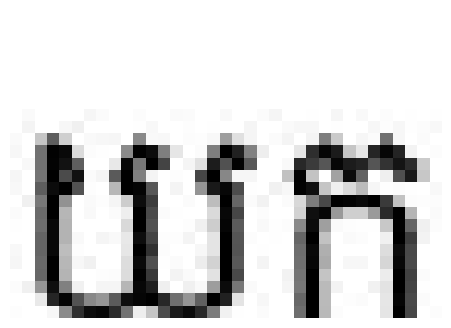

Generated text: 


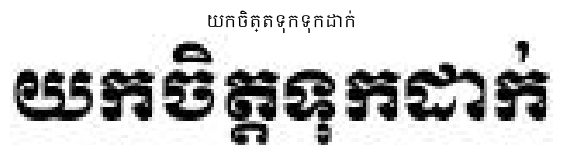

Generated text: យកចិត្តទុកទុកដាក់


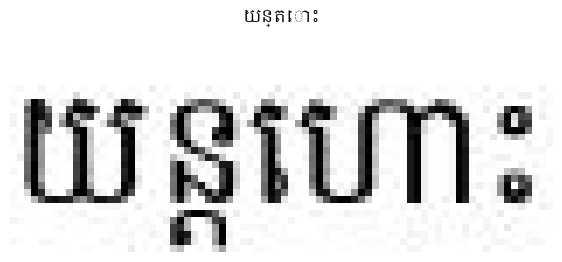

Generated text: យន្តោះ


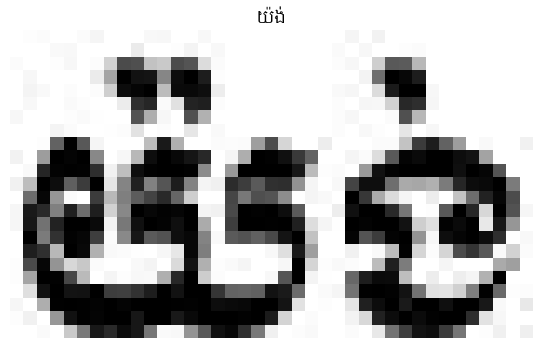

Generated text: យ៉ង់


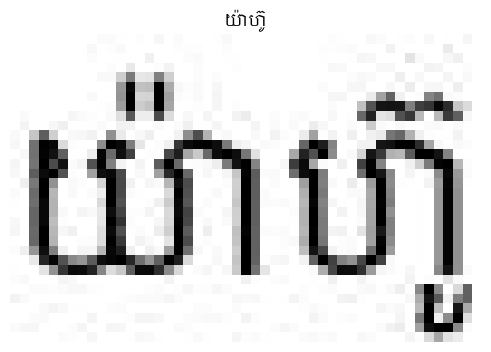

Generated text: យ៉ាហ៊ូូ


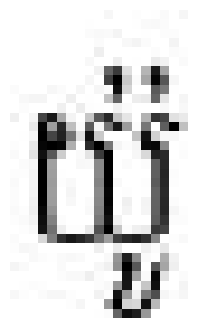

Generated text: 


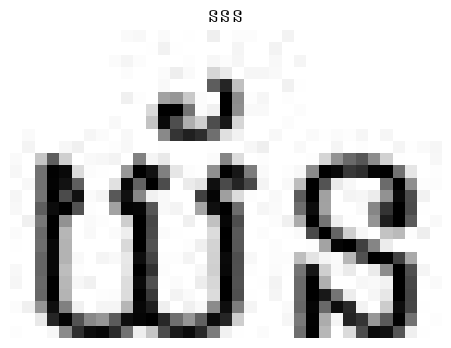

Generated text: ននន


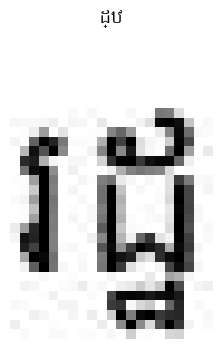

Generated text: ដ្ឋ


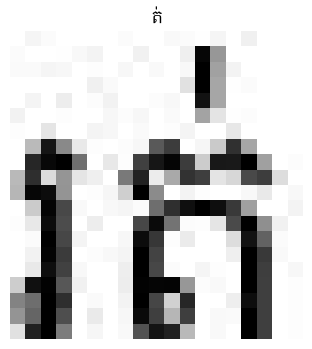

Generated text: ត់


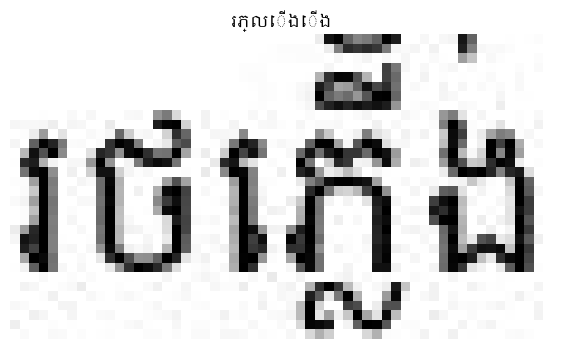

Generated text: រភ្លើងើង


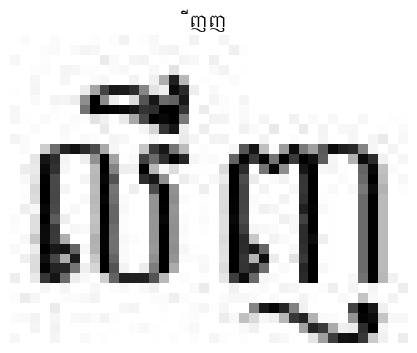

Generated text: ីីីញញ


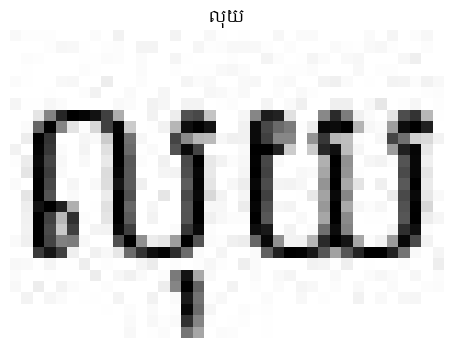

Generated text: លុយ


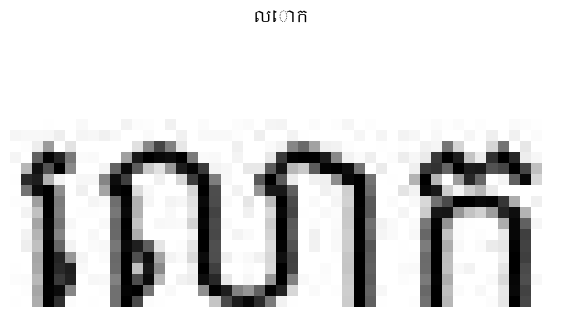

Generated text: លោក


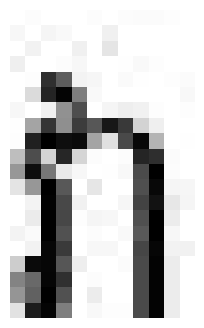

Generated text: 


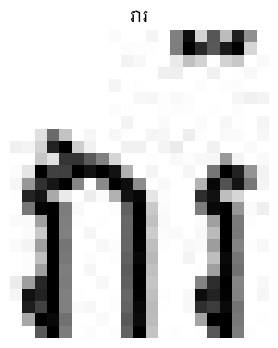

Generated text: រារ


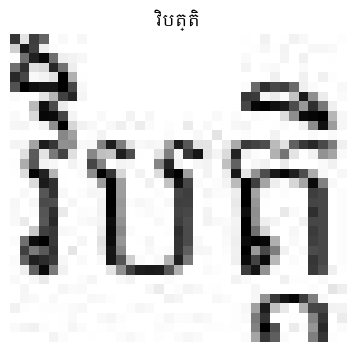

Generated text: វិបត្តិ


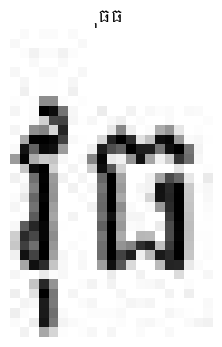

Generated text: ុធធ


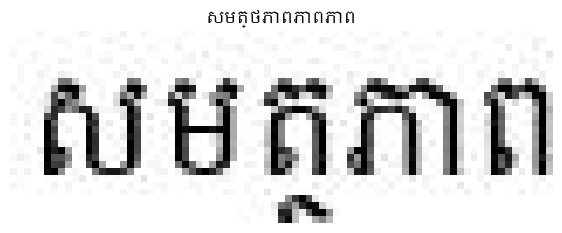

Generated text: សមត្ថភាពភាពភាព


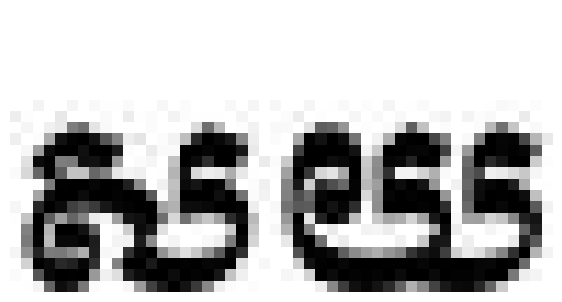

Generated text: 


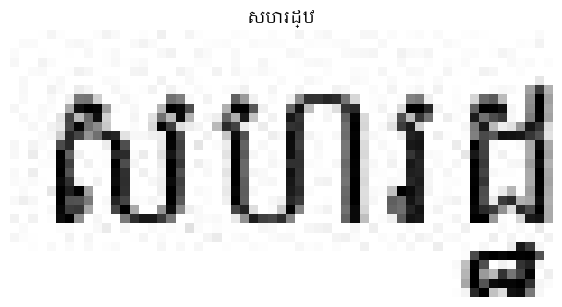

Generated text: សហរដ្ឋ


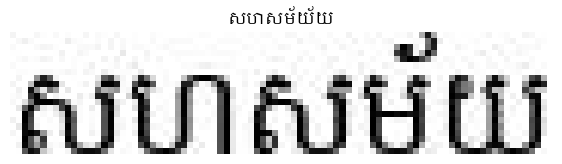

Generated text: សហសម័យ័យ


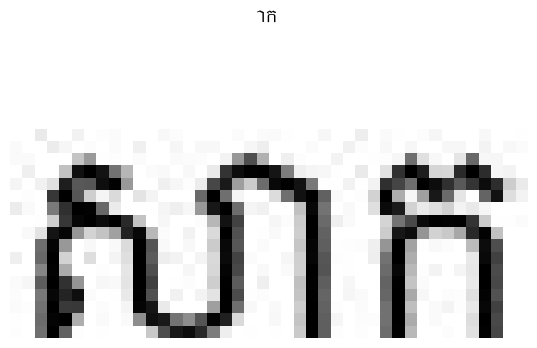

Generated text: ាក


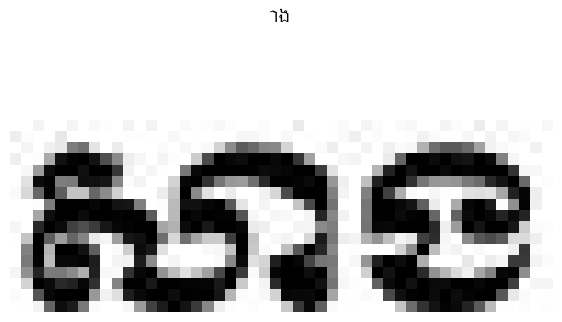

Generated text: ាង


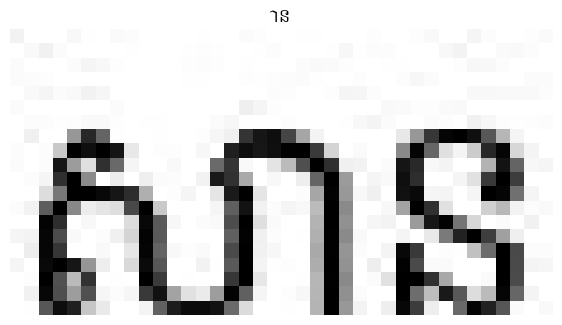

Generated text: ាន


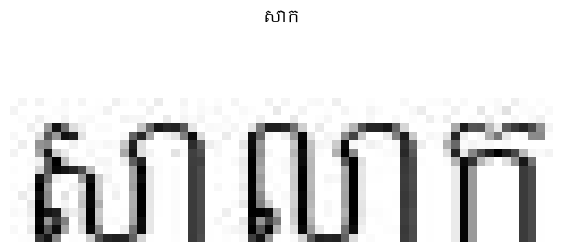

Generated text: សាក


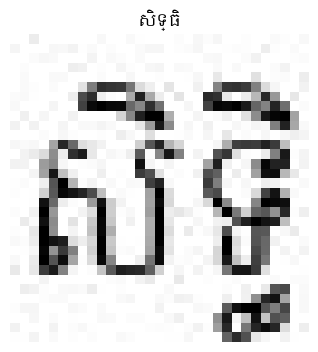

Generated text: សិិិិទ្ធិ


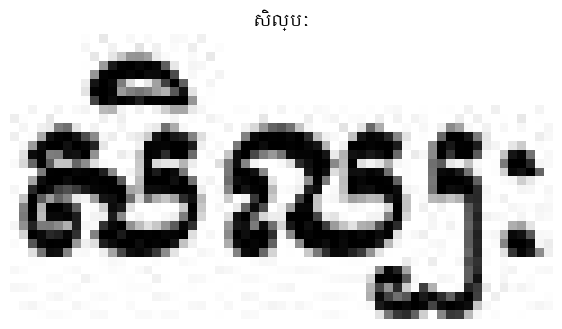

Generated text: សិិិល្បៈ


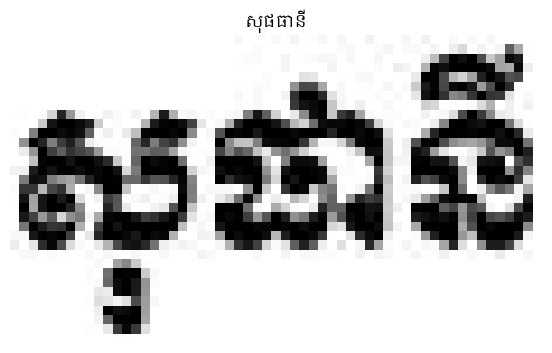

Generated text: សុផធានី


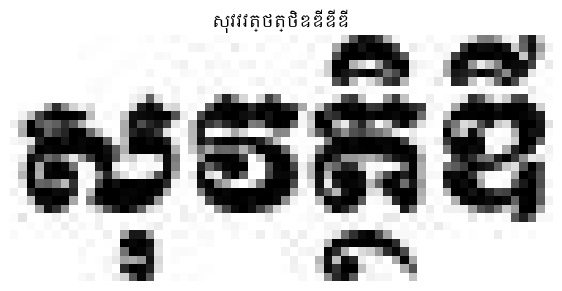

Generated text: សុវវវត្ថត្ថិឌឌីឌីឌីីីីី


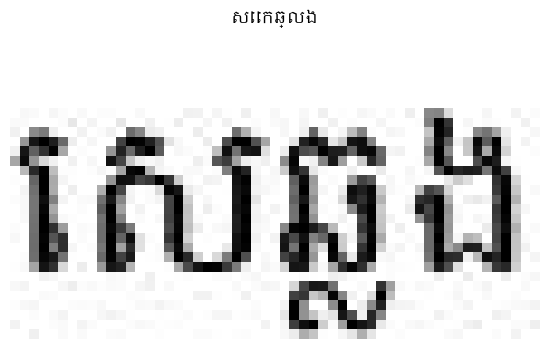

Generated text: សេេកឆ្លង


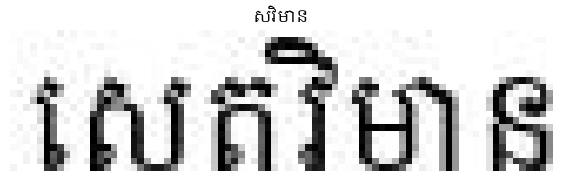

Generated text: សវិមាន


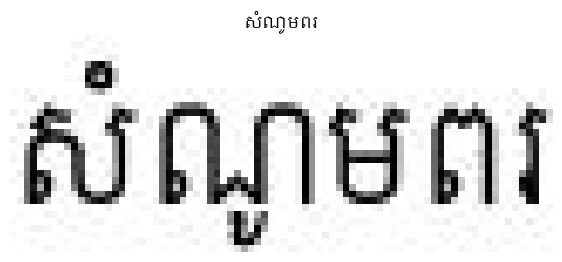

Generated text: សំណូមពរ


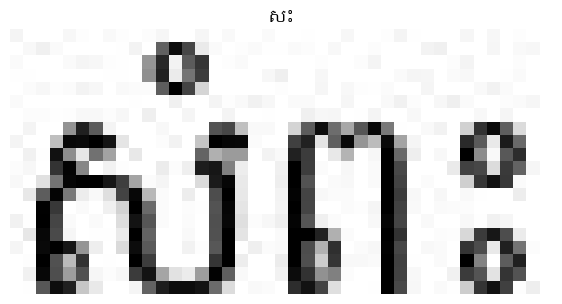

Generated text: សះ


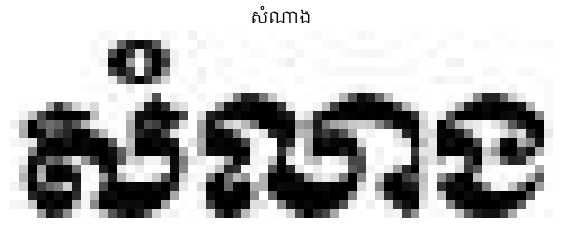

Generated text: សំណាង


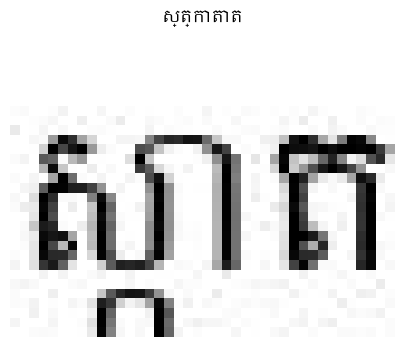

Generated text: ស្ត្កាតាត


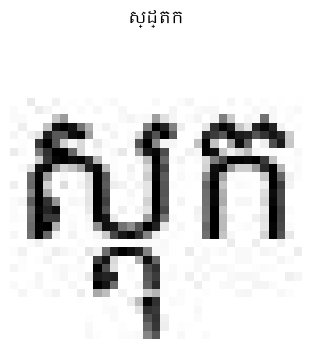

Generated text: ស្ដ្តក


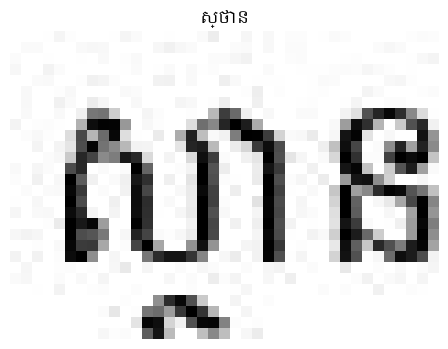

Generated text: ស្ថាន


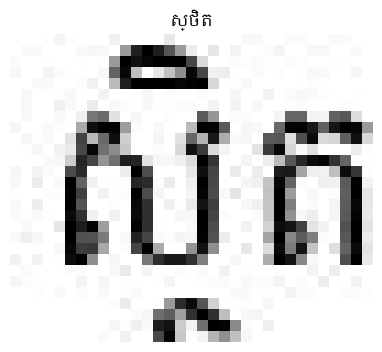

Generated text: ស្ថិត


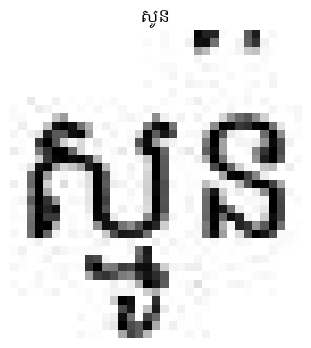

Generated text: សូន


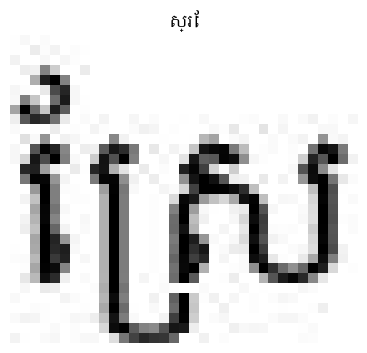

Generated text: ស្រែ


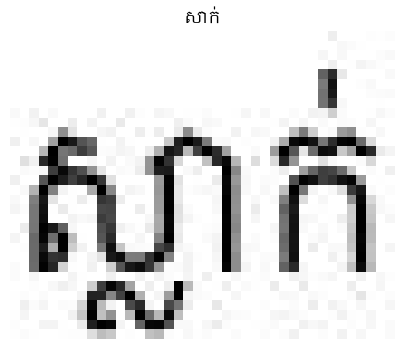

Generated text: សាក់


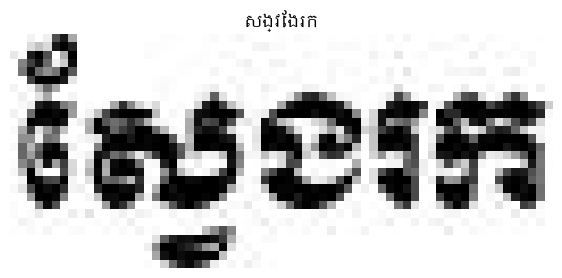

Generated text: សង្វែងរក


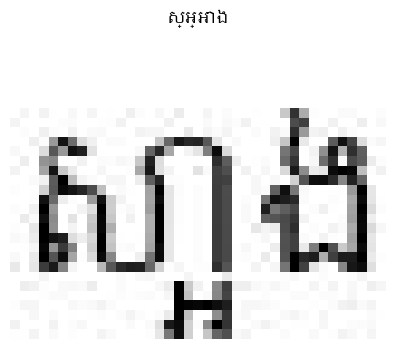

Generated text: ស្អ្អាង


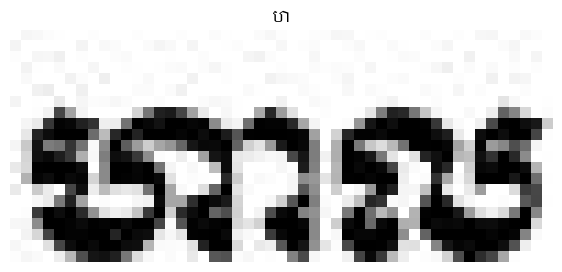

Generated text: ហ


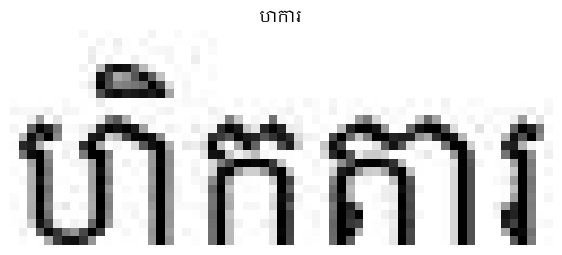

Generated text: ហការ


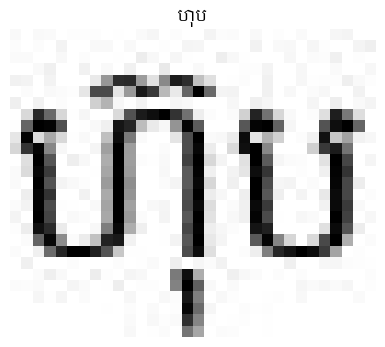

Generated text: ហុប


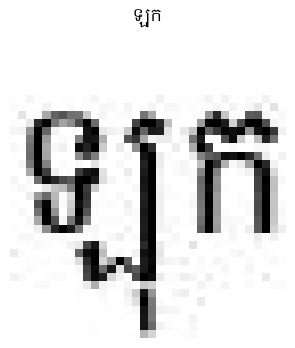

Generated text: ឡុក


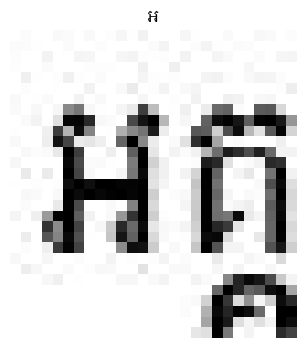

Generated text: អ


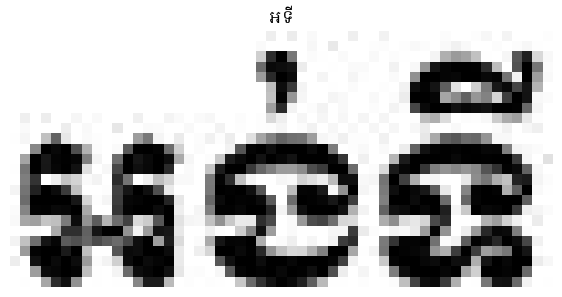

Generated text: អទី


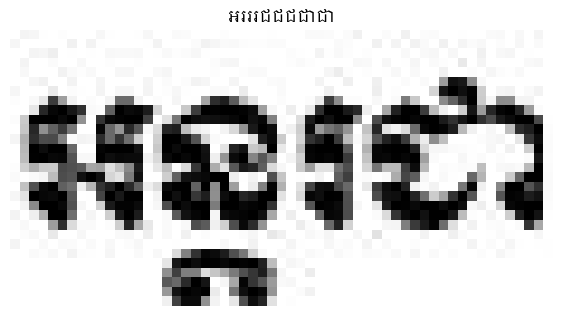

Generated text: អរររជជជជាជា


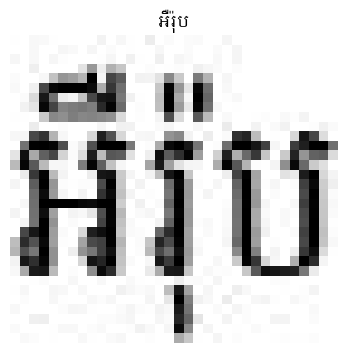

Generated text: អឺរ៉ុប


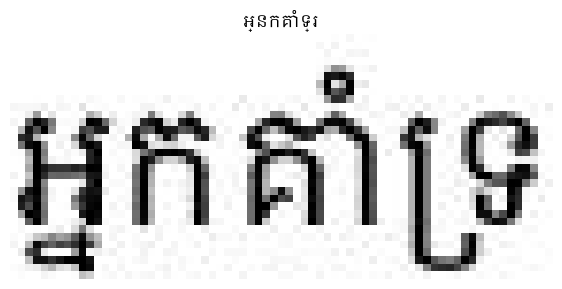

Generated text: អ្នកគាំទ្រ


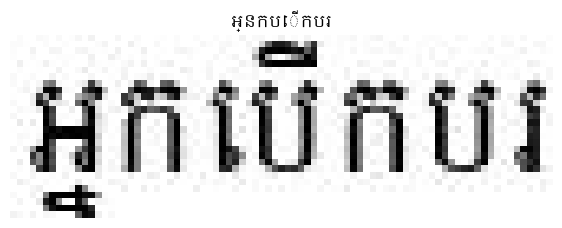

Generated text: អ្នកបើកបរ


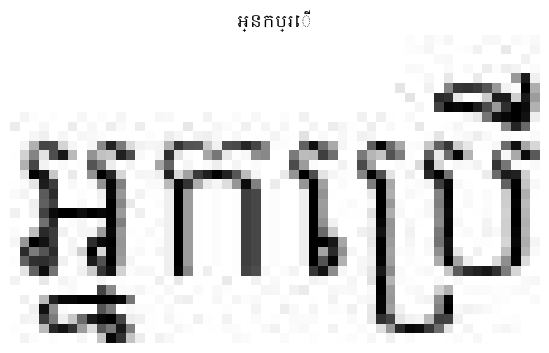

Generated text: អ្នកប្រើ


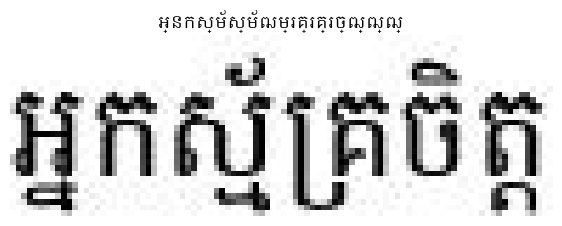

Generated text: អ្នកស្ម័ស្ម័ឍម្រគ្រគ្រច្ឍ្ឍ្ឍ្


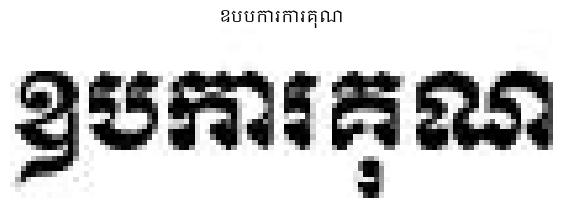

Generated text: ឧបបការការគុណ


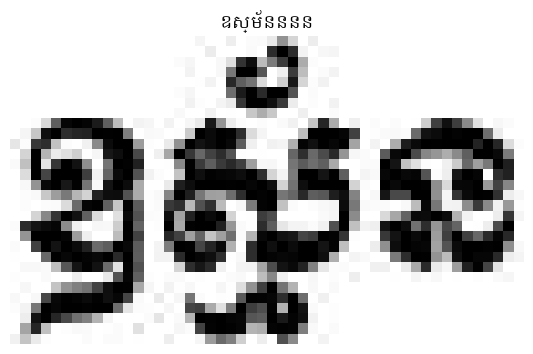

Generated text: ឧស្ម័័នននន


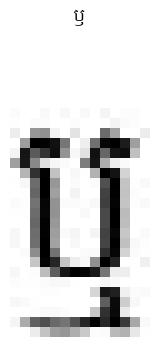

Generated text: ឫ


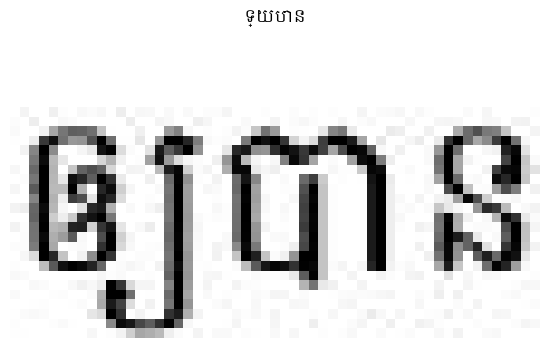

Generated text: ទ្យបាន


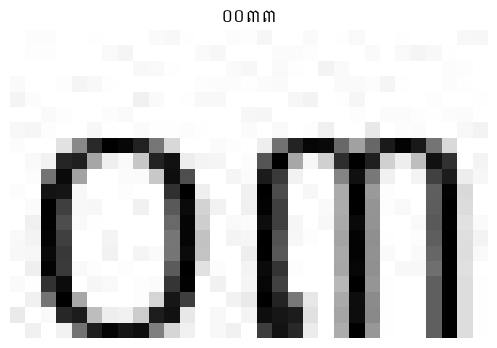

Generated text: ០០៣៣


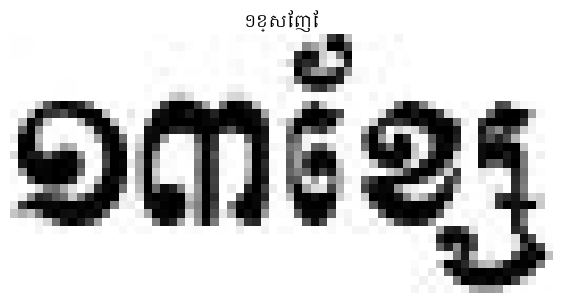

Generated text: ១ខ្សែញែ


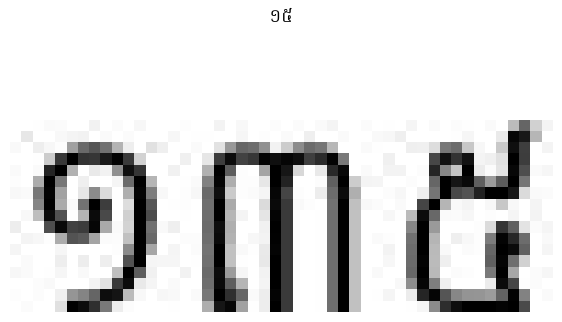

Generated text: ១៥


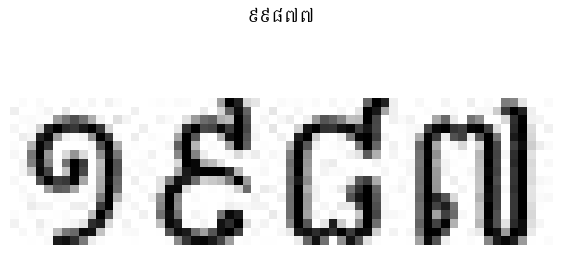

Generated text: ៩៩៨៧៧


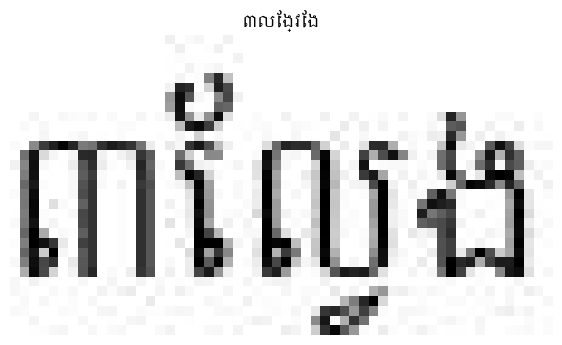

Generated text: ៣លែង្វែង


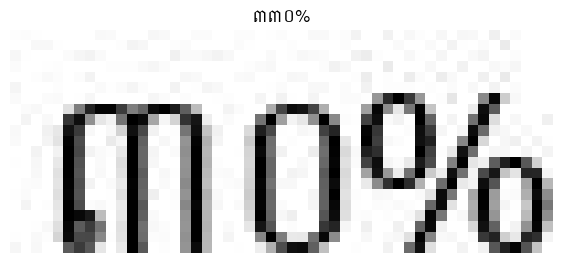

Generated text: ៣៣០%


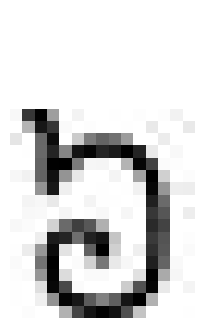

Generated text: 


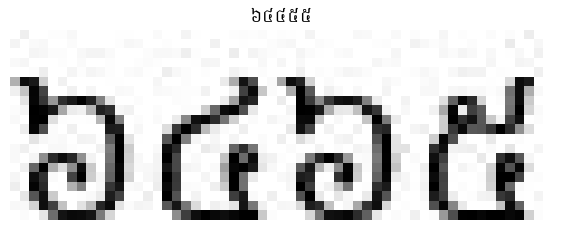

Generated text: ៦៤៤៥៥


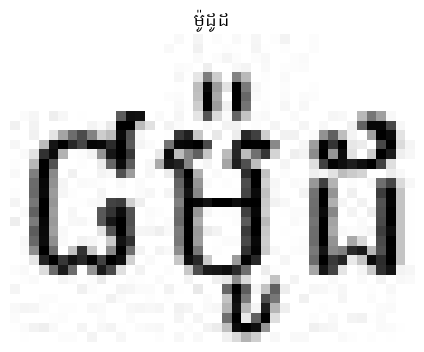

Generated text: ម៉ូដូដ


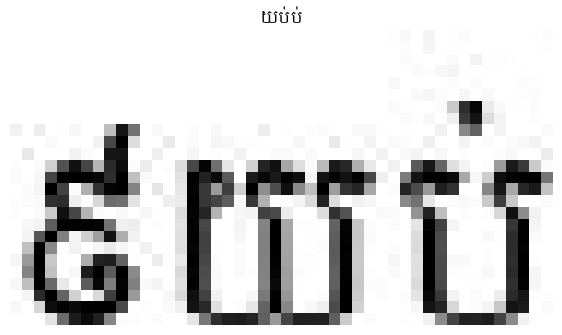

Generated text: យប់ប់


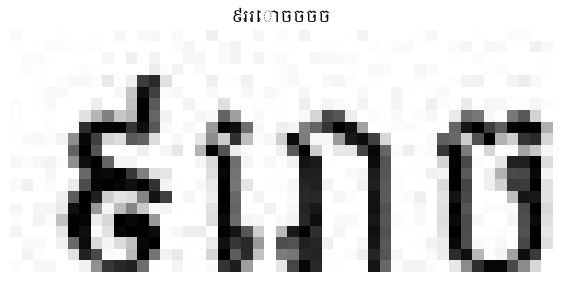

Generated text: ៩ររោចចចច


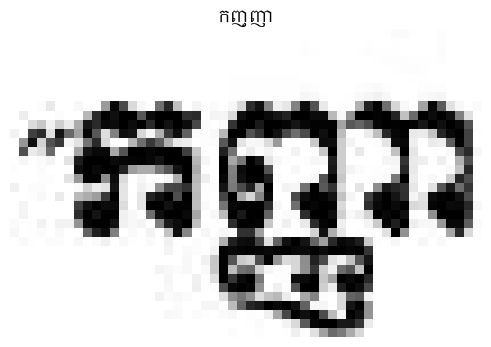

Generated text: កញ្ញា


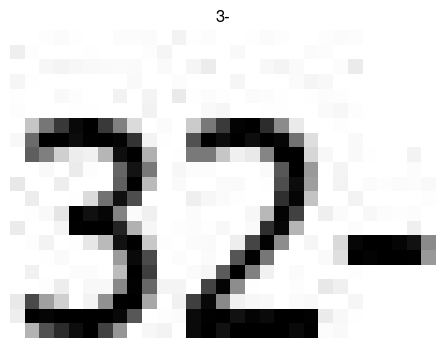

Generated text: 3-


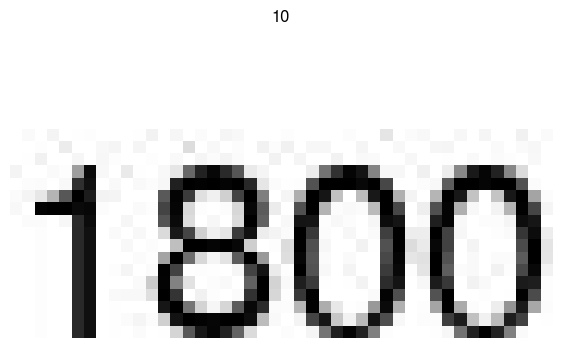

Generated text: 10


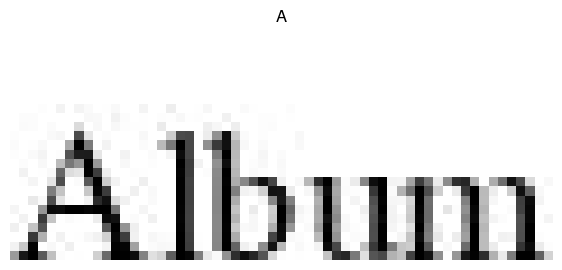

Generated text: A


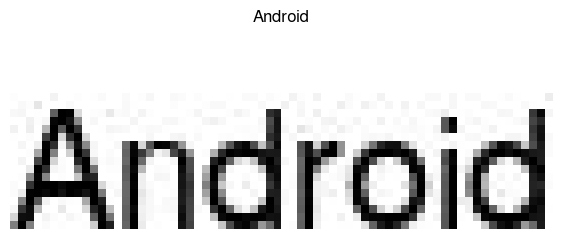

Generated text: Android


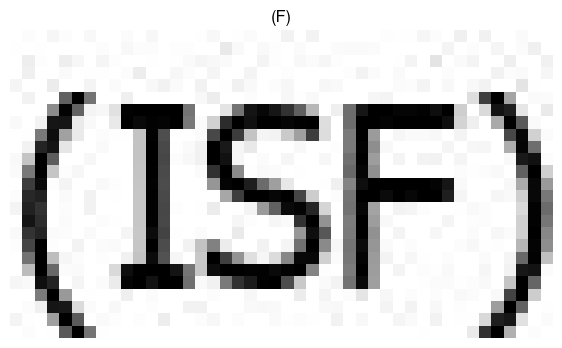

Generated text: (F)


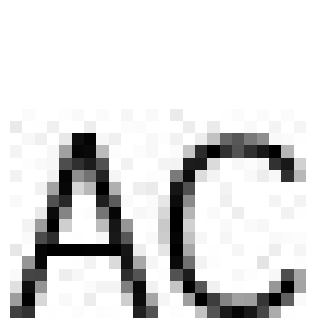

Generated text: 


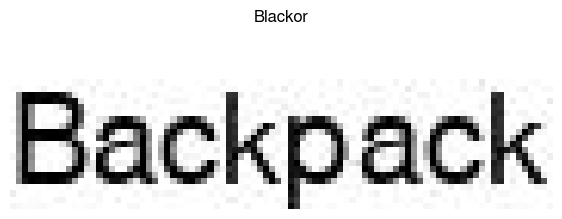

Generated text: Blackor


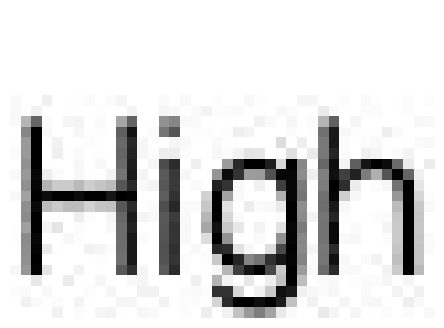

Generated text: 


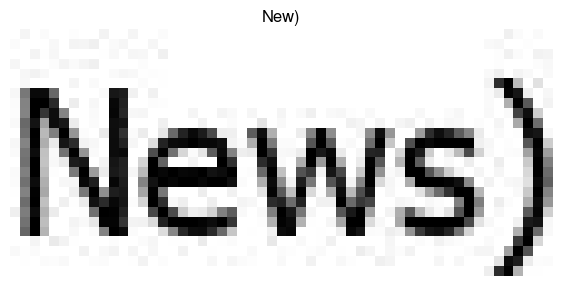

Generated text: New)


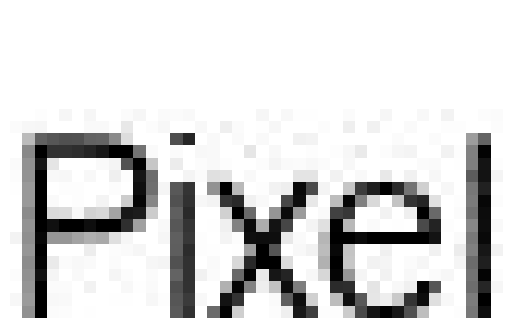

Generated text: 


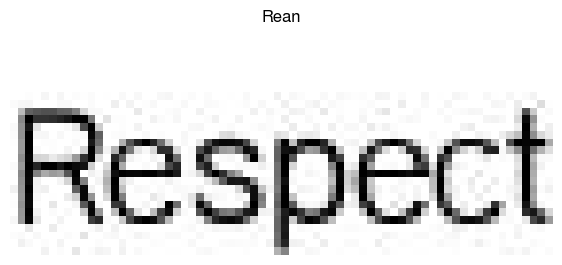

Generated text: Rean


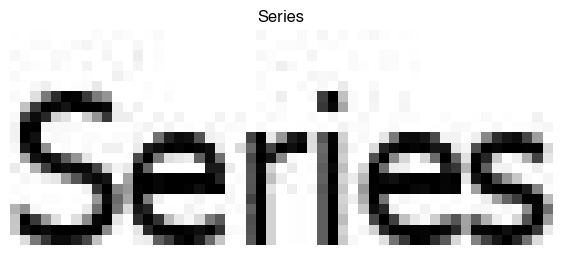

Generated text: Series


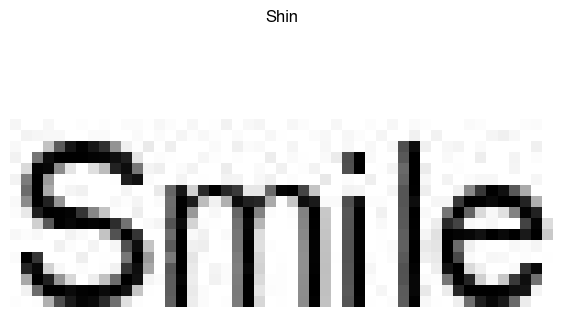

Generated text: Shin


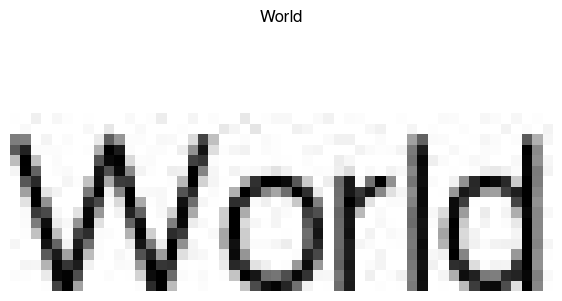

Generated text: World


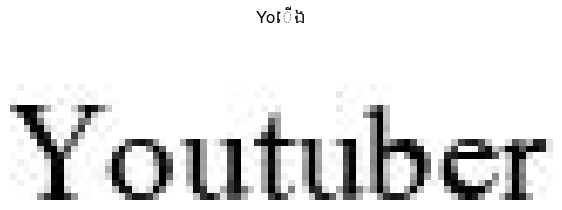

Generated text: Yoើង


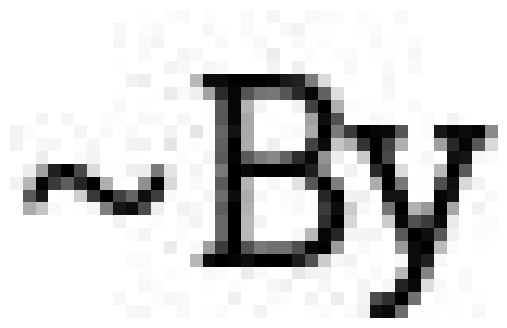

Generated text: 


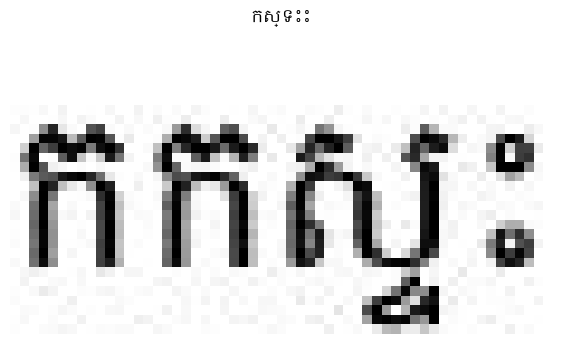

Generated text: កស្ទះះ


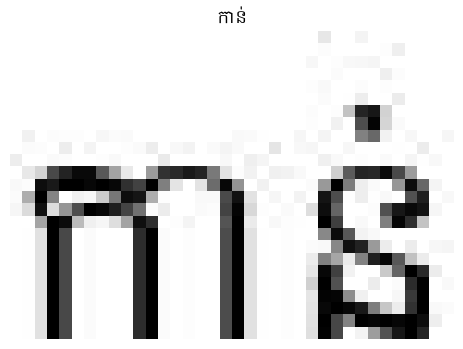

Generated text: កាន់


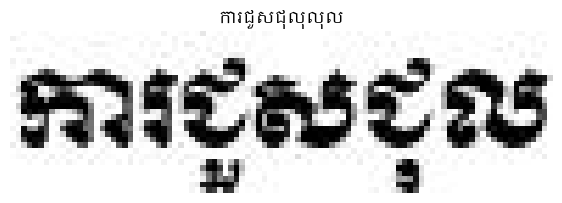

Generated text: ការជួសជុលុលុល


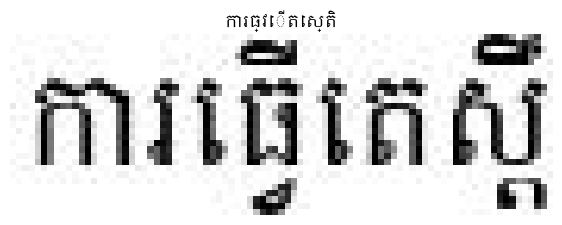

Generated text: ការធ្វើតេស្តិ


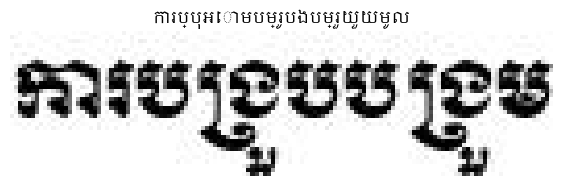

Generated text: ការប្បុអោមបម្រូបងបម្រួយួយមូល


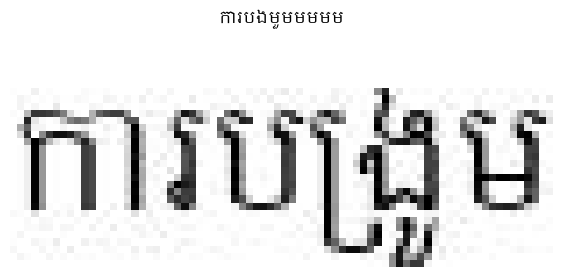

Generated text: ការបងមួមមមមម


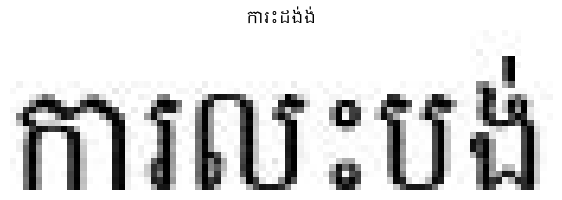

Generated text: ការះដង់ង់


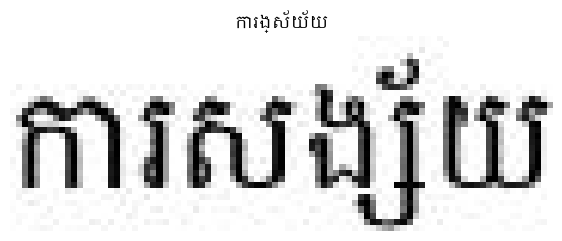

Generated text: ការង្ស័យ័យ


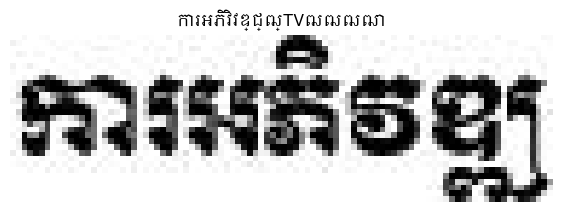

Generated text: ការអភិវិវឌ្ជ្ឍ្TVឍឍឍឍា


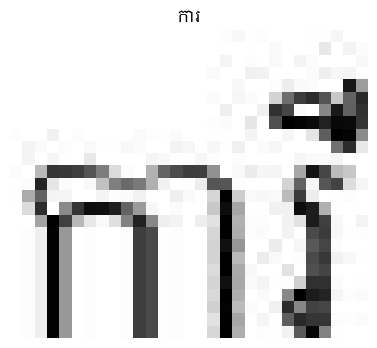

Generated text: ការ


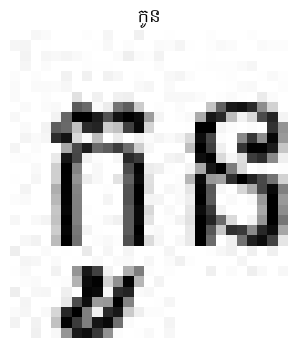

Generated text: កូន


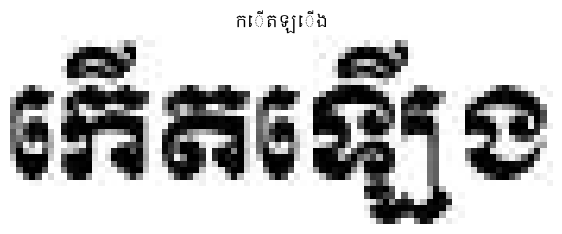

Generated text: កើតឡើង


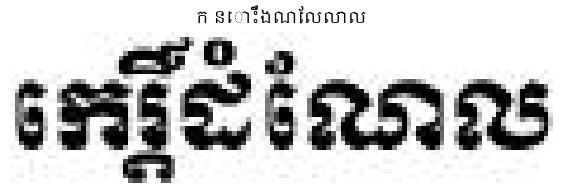

Generated text: ក នោះ័ឹងណែលលាល


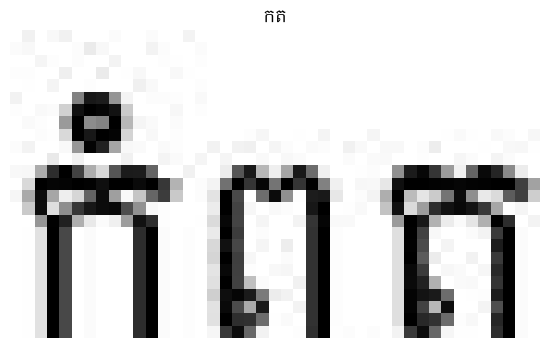

Generated text: កត


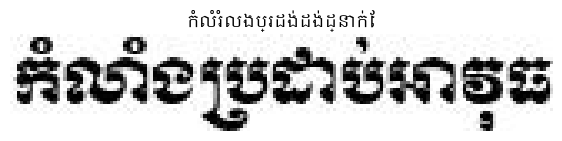

Generated text: កំលំរំលងប្រដង់ដង់ដ្នាក់ែ


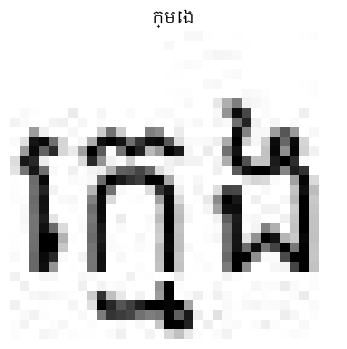

Generated text: ក្មេង


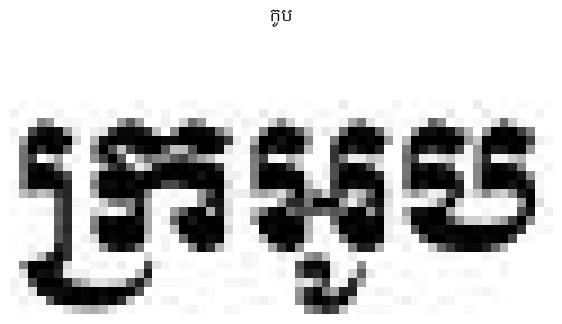

Generated text: កូប


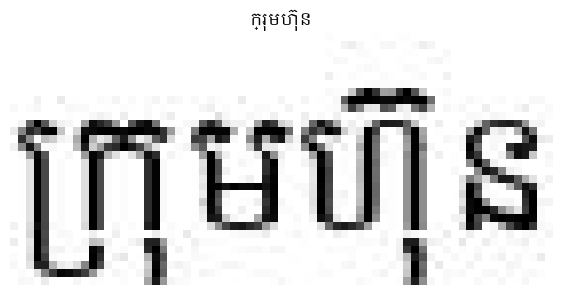

Generated text: ក្រុមហ៊ុន


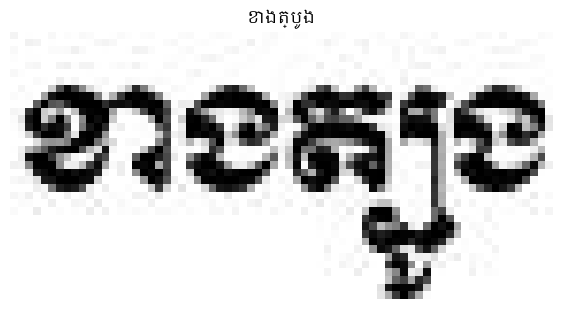

Generated text: ខាងត្បូង


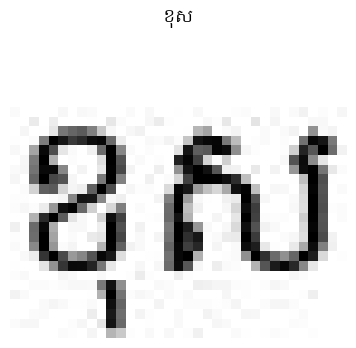

Generated text: ខុស


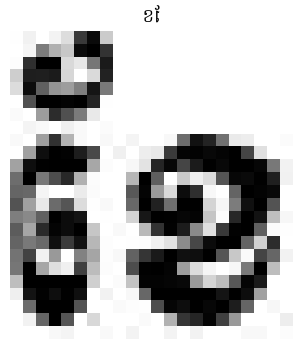

Generated text: ខែ


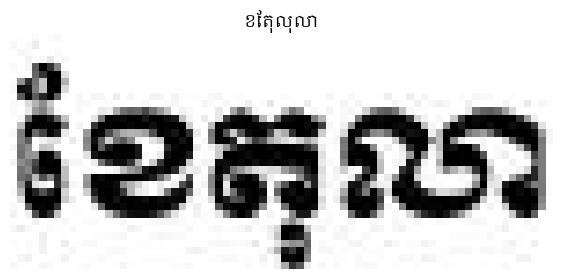

Generated text: ខែតុលុលា


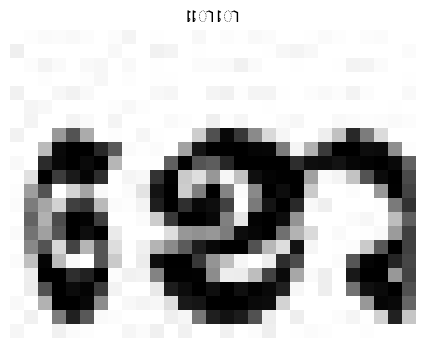

Generated text: េោោ


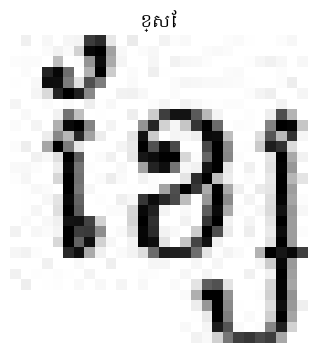

Generated text: ខ្សែ


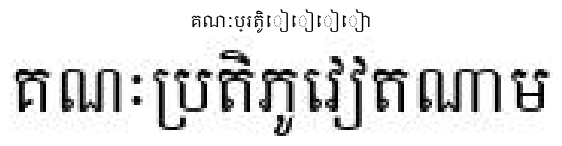

Generated text: គណៈប្រតិូៀៀៀៀា


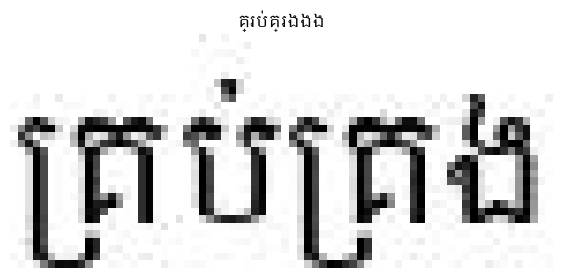

Generated text: គ្រប់គ្រងងង


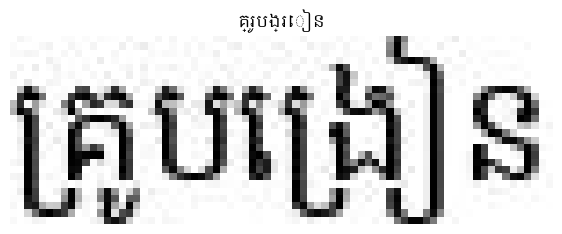

Generated text: គ្រូបង្រៀន


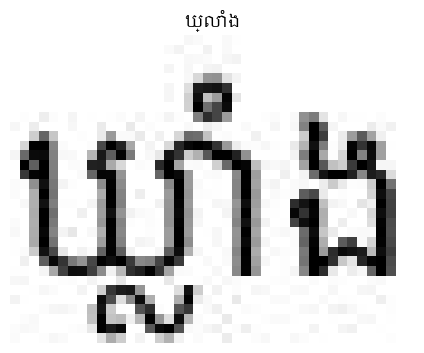

Generated text: ឃ្លាំង


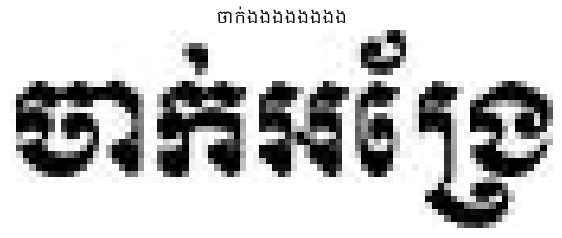

Generated text: ចាក់ងងងងងងងង


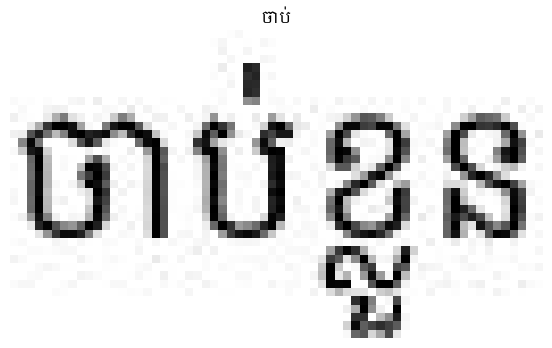

Generated text: ចាប់


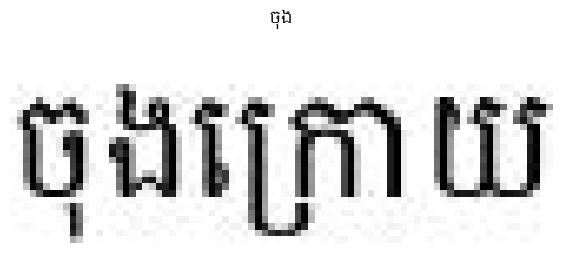

Generated text: ចុង


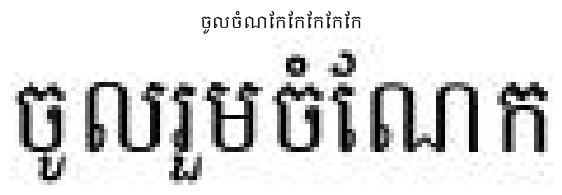

Generated text: ចូលចំណែកែកែកែកែក


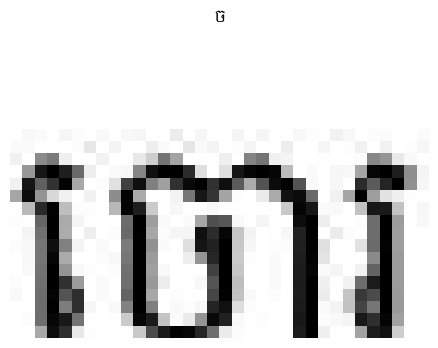

Generated text: ច


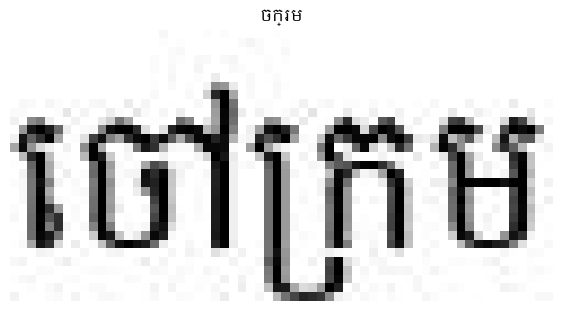

Generated text: ចក្រម


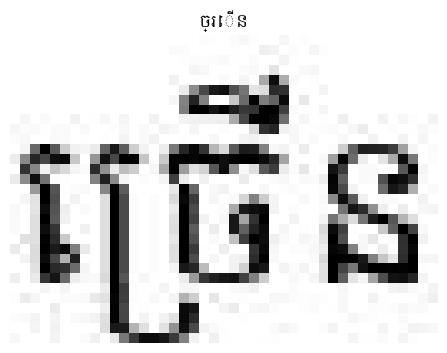

Generated text: ច្រើន


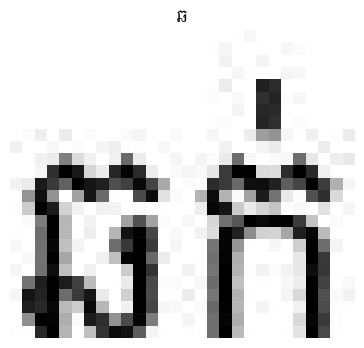

Generated text: ឆ


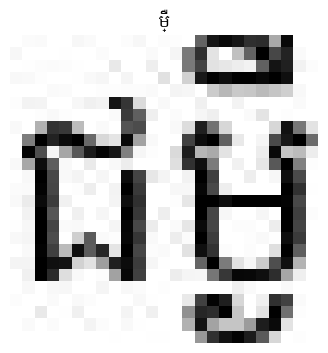

Generated text: ម្ឺឺឺឺឺឺ


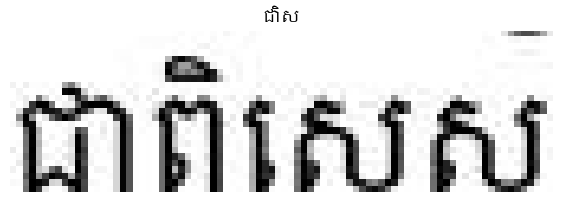

Generated text: ជាិស


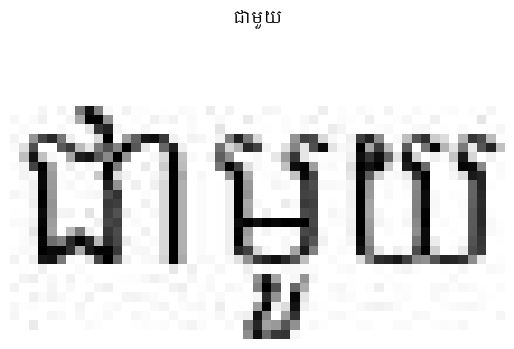

Generated text: ជាមួយ


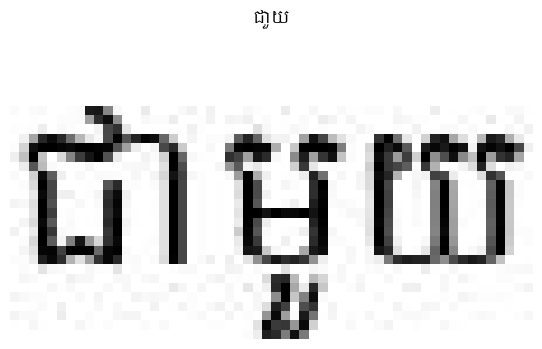

Generated text: ជាួយ


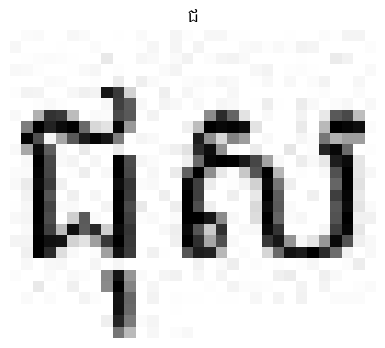

Generated text: ជ


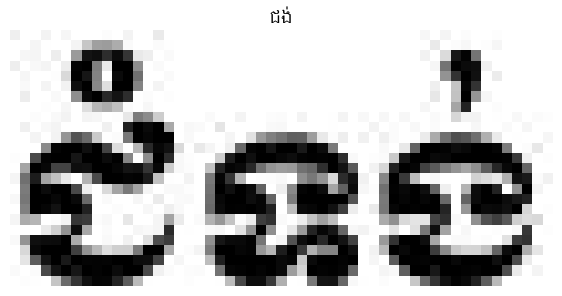

Generated text: ជង់


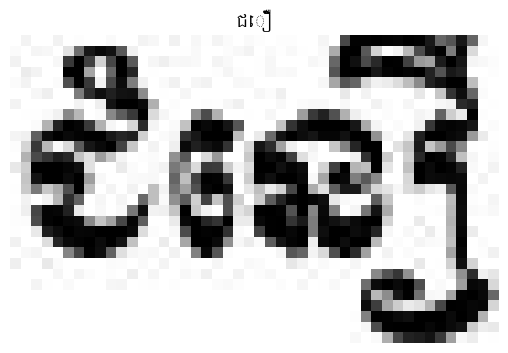

Generated text: ជឿី


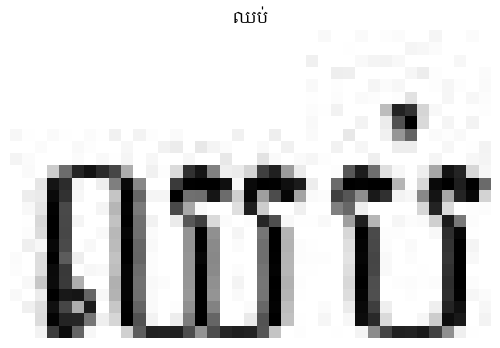

Generated text: ឈប់


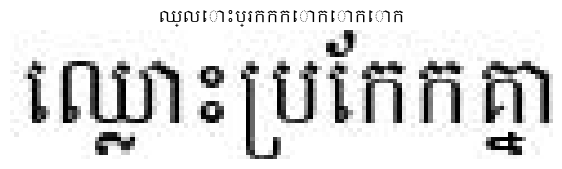

Generated text: ឈ្លោះប្រកកកោកោកោក


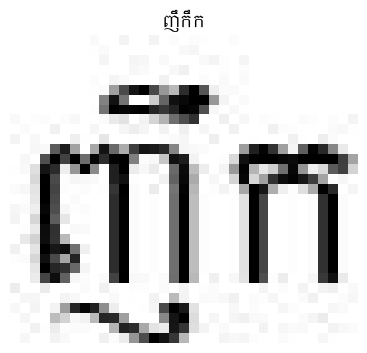

Generated text: ញឹកឹក


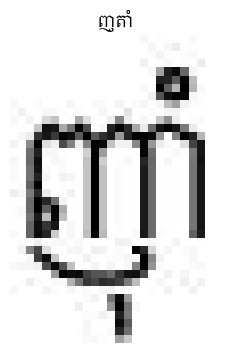

Generated text: ញ្តាំ


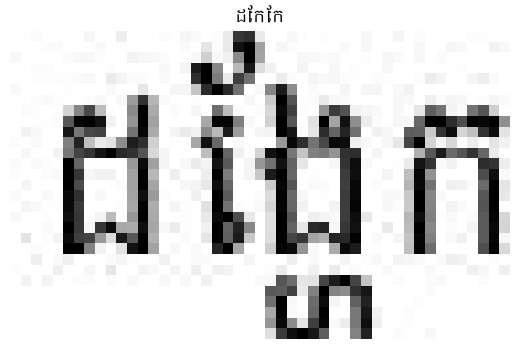

Generated text: ដែកែក


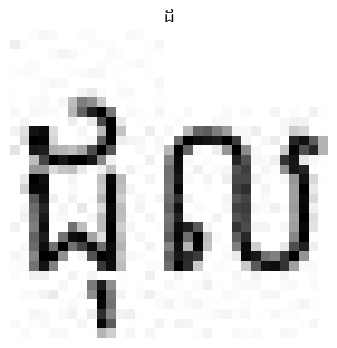

Generated text: ដ


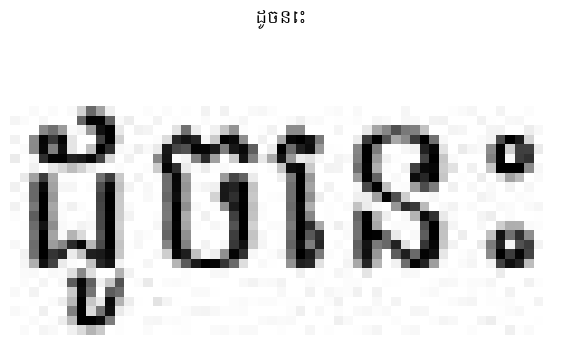

Generated text: ដូចនេះ


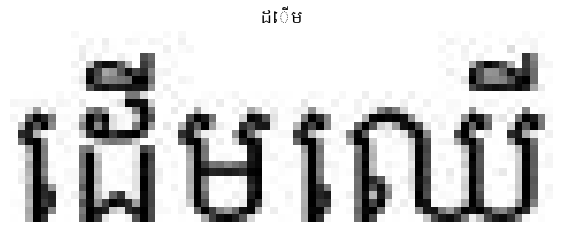

Generated text: ដើម


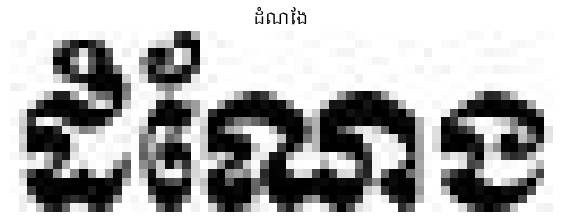

Generated text: ដំណែង


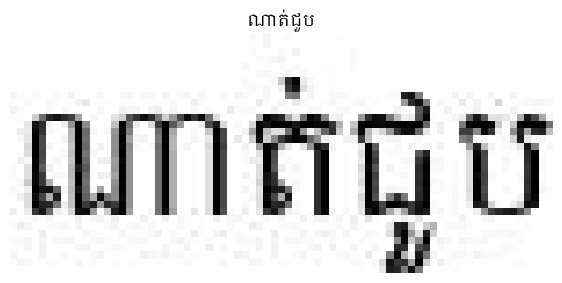

Generated text: ណាត់ជួប


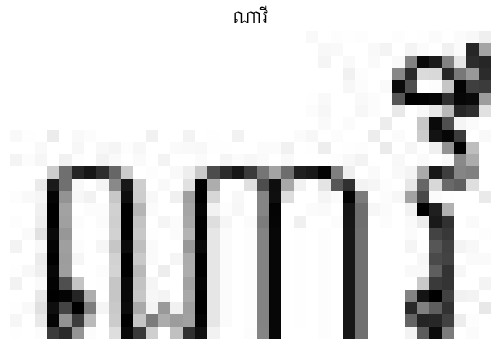

Generated text: ណាវី


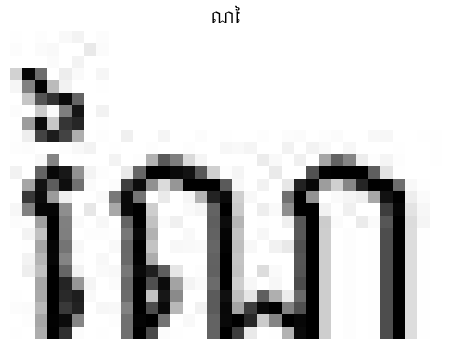

Generated text: ណៃ


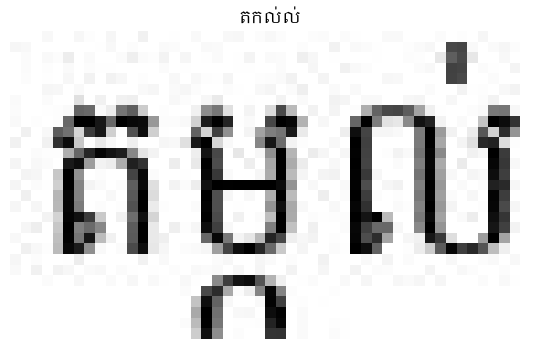

Generated text: តកល់ល់


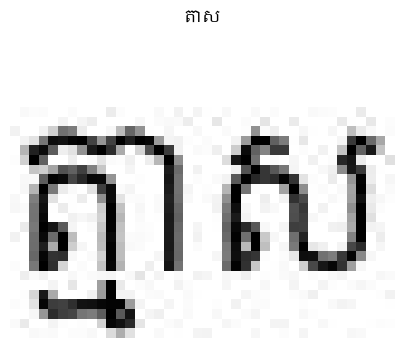

Generated text: តាស


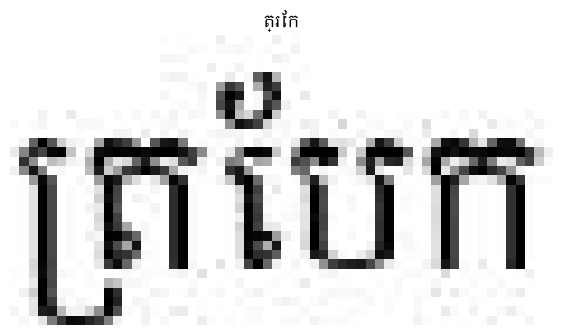

Generated text: ត្រែក


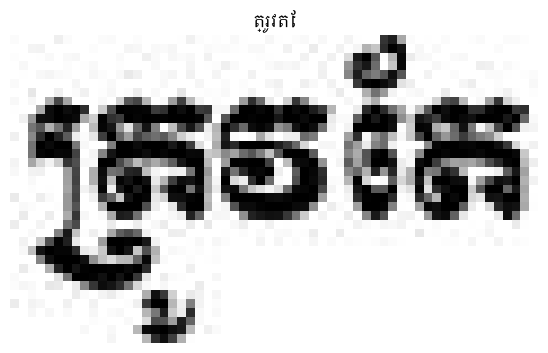

Generated text: ត្រូវតែ


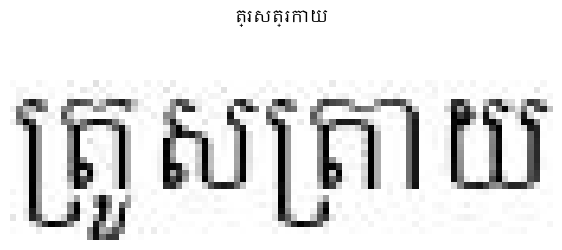

Generated text: ត្រសត្រកាយ


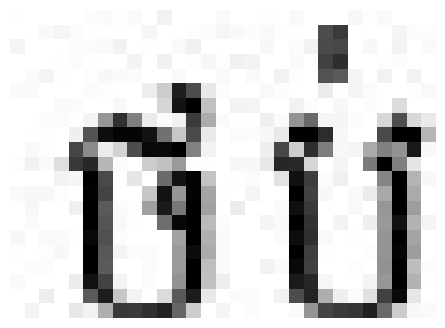

Generated text: 


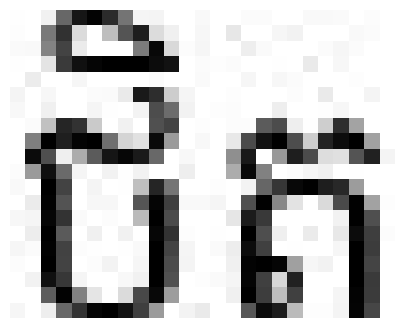

Generated text: 


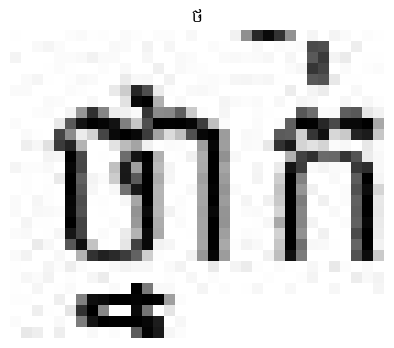

Generated text: ថ


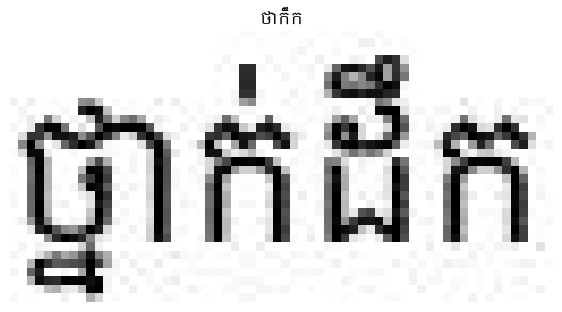

Generated text: ថាក់ឹក


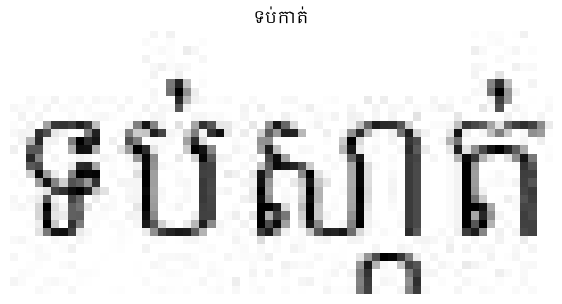

Generated text: ទប់កាត់


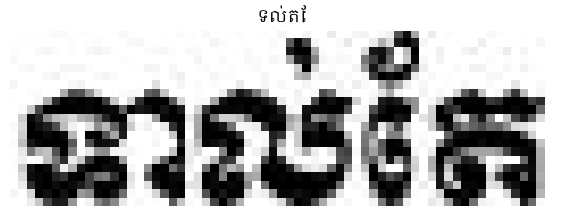

Generated text: ទល់តែ


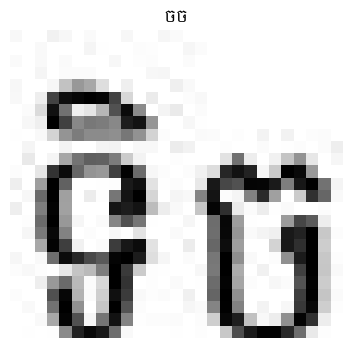

Generated text: ចច


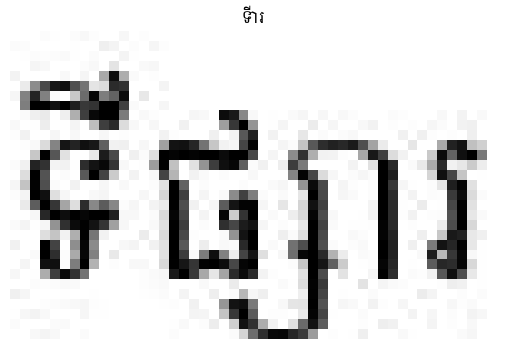

Generated text: ទីារ


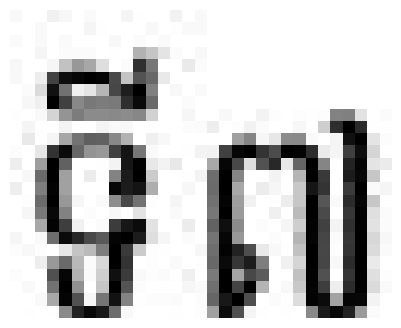

Generated text: 


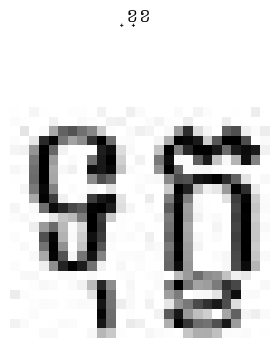

Generated text: ្ខ្ខ


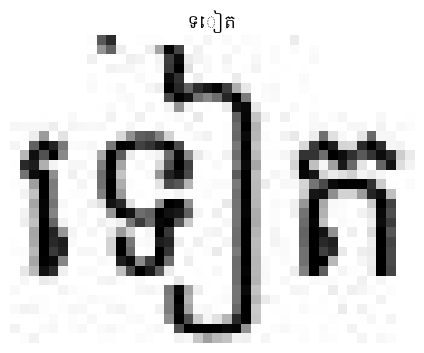

Generated text: ទៀត


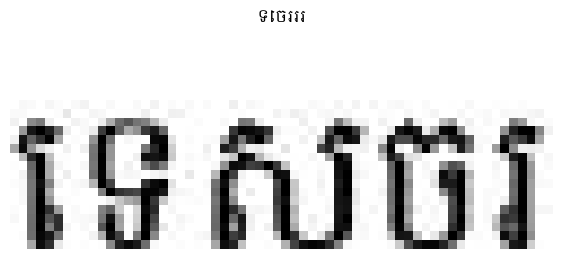

Generated text: ទេចរររ


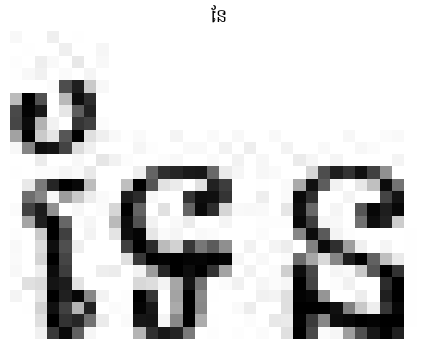

Generated text: ែន


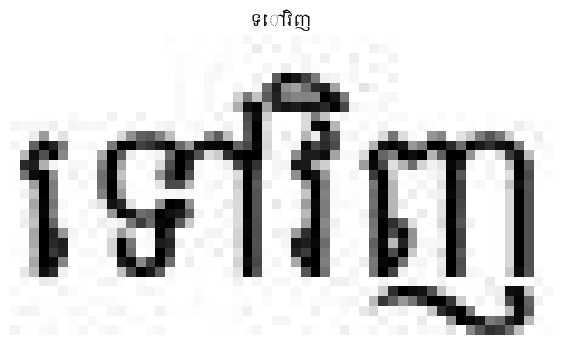

Generated text: ទៅវិញ


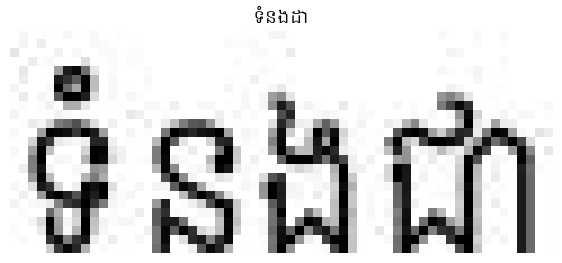

Generated text: ទំនងដា


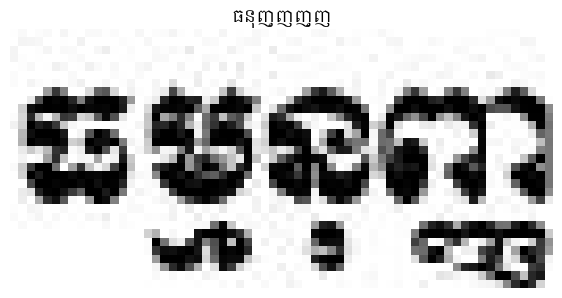

Generated text: ធនុញ្ញញ្ញ


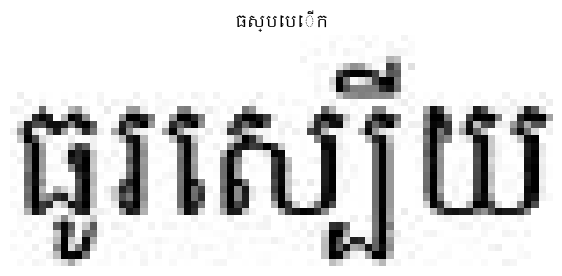

Generated text: ធស្បេបើក


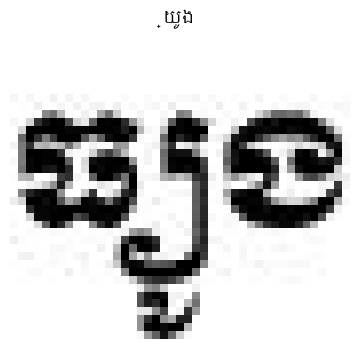

Generated text: ្យូង


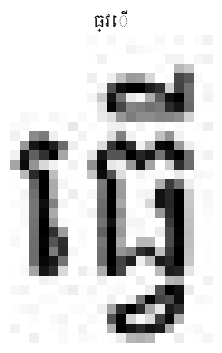

Generated text: ធ្វើ


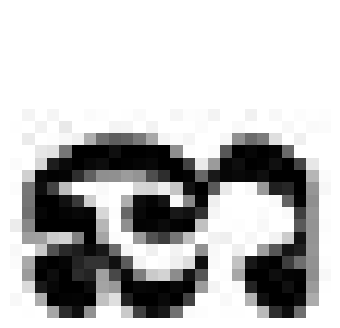

Generated text: 


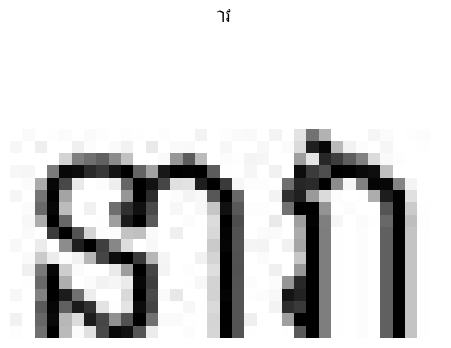

Generated text: ាវ


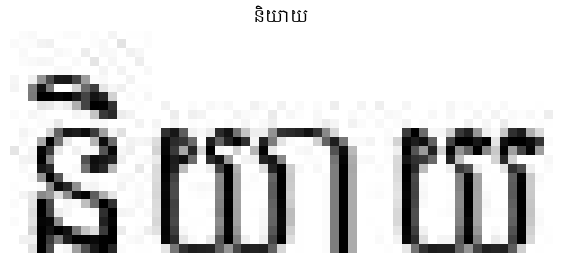

Generated text: និយាយ


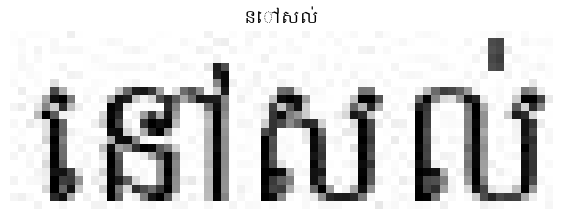

Generated text: នៅសល់


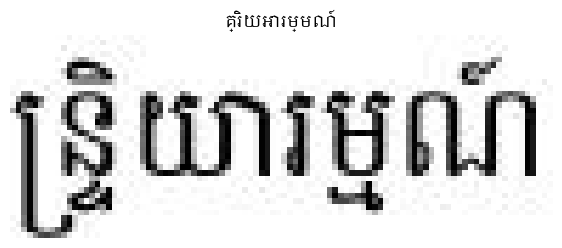

Generated text: គ្រិយអារម្មណ៍


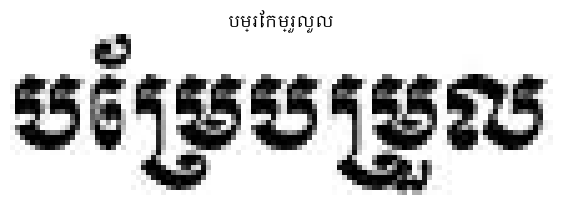

Generated text: បម្រែកម្រួលួល


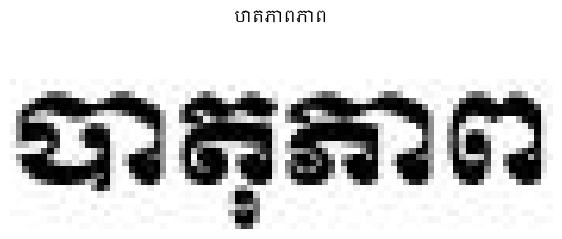

Generated text: បាតភាពភាព


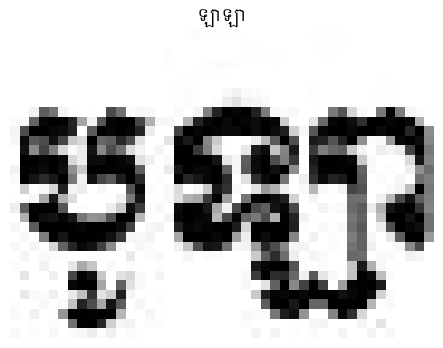

Generated text: ឡាឡា


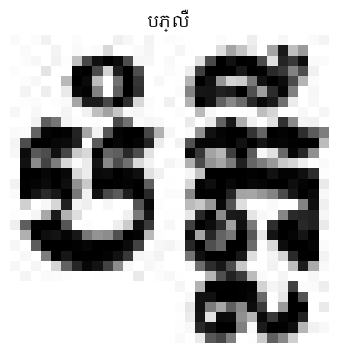

Generated text: បភ្លឺឺឺ


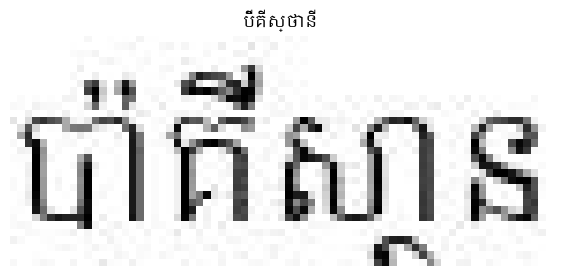

Generated text: ប៉ីគីស្ថានី


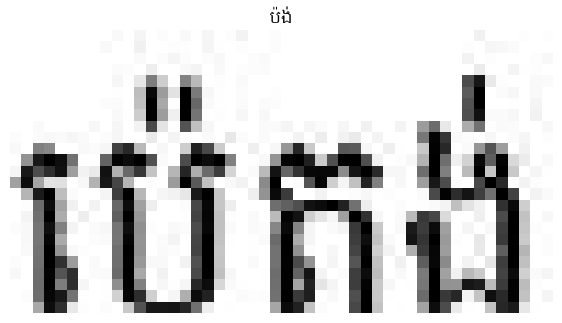

Generated text: ប៉ង់


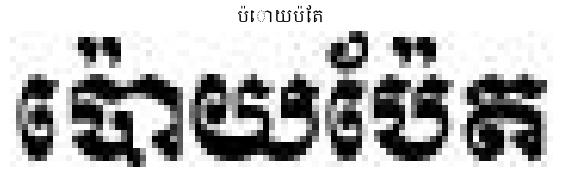

Generated text: ប៉ោយប៉ែត


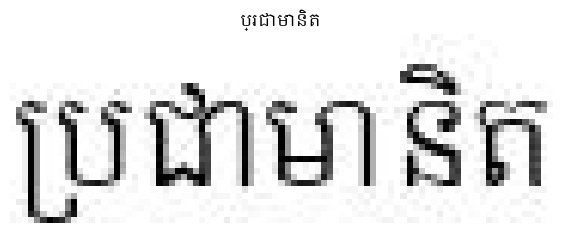

Generated text: ប្រជាមានិត


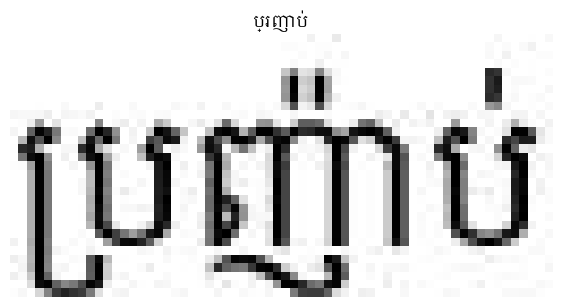

Generated text: ប្រញាប់


In [24]:
eval_new_data(
    data_path=os.path.join(DatasetConfig.DATA_ROOT, 'data_test', '*'),
    num_samples=300
)